# Module 4: Introduction to Nowcasting
## The incident review, or could the festival have been warned?

On the evening of 19 June 2021 an open-air music festival was running on the banks of the Meuse at
Namur, in Belgium. The headline act was due on stage at 21:00 UTC. During that evening a mesoscale
convective system, meaning a cluster of thunderstorms organised well enough to behave as one large
storm, moved north out of France. It put more than 30 mm of rain per hour over the festival site.

You have been convened to the review panel that meets after an event like this. The panel has one
deliverable. It must write a verdict stating whether a warning was possible, and from what time.

Six steps follow, and each supplies one piece of the evidence. You will commit to a verdict three
separate times as that evidence accumulates. The first comes before you have used any method at
all. The second comes from a deterministic nowcast, meaning a single predicted future. The third
comes from an ensemble, meaning a set of possible futures. All three sit side by side at the end.

No answer key judges them. What teaches you is the gap between your own three verdicts, together
with the verification numbers you computed yourself.

Two kinds of prompt appear as you go.

| Flag | Meaning |
|---|---|
| 🔴 **VERDICT** | A position the panel puts in its report. You will be asked to defend it. |
| 🟠 **COMMITMENT** | Not a verdict. A statement of what your answer currently rests on, written before you are shown whether it holds. |

The rainfall data is RADCLIM, the radar archive of the Royal Meteorological Institute of Belgium,
released under a CC-BY-4.0 licence. It merges radar with rain gauges and reports one rain rate per
square kilometre every five minutes. The [MLCast](https://github.com/mlcast-community/mlcast-datasets)
community catalog serves it. The nowcasting library is [pysteps](https://pysteps.readthedocs.io).

This notebook holds the solutions. Every blank is filled
in. Each verdict carries a model answer, which is one defensible way of arguing the case rather
than the only one. The exercise version is `Nowcasting.ipynb`.

In [1]:
# The hackathon environment ships neither pysteps nor the MLCast catalog.
# NOTE: opencv is required by the Lucas-Kanade optical flow inside pysteps. Colab
# ships it, most local environments do not, so we ask for it explicitly - without
# it, motion.get_method("LK") raises MissingOptionalDependency.
#
# %pip (not !pip) installs into the kernel actually running this notebook.
%pip install -q mlcast-datasets pysteps cartopy opencv-python-headless

Note: you may need to restart the kernel to use updated packages.


---
## Background: what nowcasting is, and what it is for

You are used to weather forecasts produced by a numerical weather prediction model, which
integrates the equations of the atmosphere forward in time. A nowcast works differently. It takes
the most recent observations, usually radar, and carries them forward without solving those
equations at all.

pysteps assembles a nowcast from a few components. It first estimates how the rainfall field is
moving, which gives a motion field. It then models how that field evolves as it travels. It can
add stochastic noise, meaning random perturbations drawn to match the statistics of real rainfall.
Finally it extrapolates the field to each lead time you asked for. Pulkkinen et al. (2019)
describe the library and its design in full.

Why use this at all, when a full model is available? Because for the first hour or two the model
is not competitive. Imhoff et al. (2020) evaluated radar nowcasts over 1,533 separate rainfall
events and found the nowcast keeps its advantage over numerical weather prediction for up to about
two hours. The exact crossover moves with the season, the type of rainfall and the size of the
area being forecast.

The price of that early skill is that extrapolation contains no physics. It moves rain around. It
does not create rain, and it does not destroy it. Every limitation this panel runs into follows
from that one property.

**Sources.** Pulkkinen, S., Nerini, D., Pérez Hortal, A. A., Velasco-Forero, C., Seed, A.,
Germann, U. and Foresti, L. (2019). Pysteps: an open-source Python library for probabilistic
precipitation nowcasting (v1.0). *Geoscientific Model Development*, 12, 4185 to 4219,
doi:10.5194/gmd-12-4185-2019. Imhoff, R. O., Brauer, C. C., Overeem, A., Weerts, A. H. and
Uijlenhoet, R. (2020). Spatial and temporal evaluation of radar rainfall nowcasting techniques on
1,533 events. *Water Resources Research*, 56(8), e2019WR026723, doi:10.1029/2019WR026723.

## 0. Setup: the archive, the site, and the domain

In [2]:
# Disable warnings
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

import mlcast_datasets
from pyproj import CRS, Transformer

from pysteps import motion, nowcasts, verification
from pysteps.utils import transformation
from pysteps.postprocessing.ensemblestats import excprob
from pysteps.visualization import plot_precip_field, quiver
from pysteps.visualization.basemaps import plot_map_cartopy
from pysteps.visualization.utils import proj4_to_cartopy, get_geogrid

%matplotlib inline

Pysteps configuration file found at: /tmp/claude-2030/-home-labonnef-Desktop-Hackathon-EUPP-Nowcasting-and-Postprocessing-Hackathon-Module-4---Introduction-to-Nowcasting/2ff08fb5-35b5-44da-bec5-cf701a142ffe/scratchpad/.venv/lib/python3.12/site-packages/pysteps/pystepsrc



In [3]:
# ---- the case ------------------------------------------------------------
EVENT_DAY   = "2021-06-19"           # the evening of the festival
T0          = "2021-06-19T20:15"     # when the panel issues its nowcast (UTC)
SITE_NAME   = "Namur"
SITE_LONLAT = (4.8720, 50.4674)      # the festival site
N_INPUT     = 12                     # input frames (1 h): DARTS needs a long series
N_LEADTIMES = 12                     # 12 x 5 min = 1 hour ahead

# ---- the two decisions that shape everything downstream -------------------
# What rain rate would stop an open-air show? Not a drizzle, and not a
# once-a-decade cloudburst either. You are choosing the event this review is about.
WARN_THR = 5.0            # mm/h

# How far around the stage do you look for that rain? A single 1 km pixel is one
# radar bin; a wide circle is half the province. Step 1 tests your choice - come
# back and change this number once you have seen what it does.
NEIGHBOURHOOD_KM = 5

# Why issue at 20:15? By then the first shower has passed the site and the rain has
# almost stopped. That is exactly when the organiser asks the question the panel
# has to answer: "it seems to be over - can we run the 21:00 set?"

In [4]:
cat = mlcast_datasets.open_catalog()
print(f"Available precipitation datasets: {list(cat.precipitation)}")

# 5-minute radar-gauge merged rain rate over Belgium (RADCLIM, mean-field-bias
# corrected), on a 1 km Belgian Lambert 2008 grid, lazily via dask
ds = cat.precipitation.be_rmi_radclim_mfb_5min.to_dask()
for k in ["long_name", "units", "product_description", "method_description"]:
    print(f"  {k:22s} {ds.rain_rate.attrs[k]}")
ds

Available precipitation datasets: ['radklim_hourly', 'radklim_5_minutes', 'dmi_10_minutes', 'it_dpc_sri_5min', 'uk_metoffice_5min', 'be_rmi_radclim_mfb_5min']


  long_name              Rain rate (QPE_MFB)
  units                  kg m-2 h-1
  product_description    Quantitative precipitation estimate
  method_description     Mean field bias correction


<xarray.Dataset> Size: 1TB
Dimensions:        (time: 726332, y: 700, x: 700, missing_times: 868)
Coordinates:
  * time           (time) datetime64[ns] 6MB 2017-01-01 ... 2023-11-30T23:55:00
  * y              (y) float64 6kB 9.995e+05 9.985e+05 ... 3.015e+05 3.005e+05
  * x              (x) float64 6kB 3.005e+05 3.015e+05 ... 9.985e+05 9.995e+05
    lat            (y, x) float64 4MB dask.array<chunksize=(700, 700), meta=np.ndarray>
    lon            (y, x) float64 4MB dask.array<chunksize=(700, 700), meta=np.ndarray>
  * missing_times  (missing_times) datetime64[ns] 7kB 2018-11-30T13:20:00 ......
    spatial_ref    int64 8B ...
Data variables:
    rain_rate      (time, y, x) float32 1TB dask.array<chunksize=(1, 700, 700), meta=np.ndarray>
Attributes:
    Conventions:                CF-1.10
    license:                    CC-BY-4.0
    institute:                  Royal Meteorological Institute of Belgium
    contact:                    Maryna Lukach <rad_op@meteo.be>
    mlcast_created_on:          2026-03-27T15:24:18.195842+00:00
    mlcast_created_by:          Simon De Kock, Lesley De Cruz <simon.de.kock@...
    mlcast_created_with:        https://github.com/mlcast-community/mlcast-da...
    mlcast_dataset_version:     0.1.1
    mlcast_dataset_identifier:  BE-radclim_mfb-rain_rate
    consistent_timestep_start:  2017-01-01T00:00:00

In [5]:
crs = CRS.from_wkt(ds[ds.rain_rate.grid_mapping].crs_wkt)
to_grid = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
SITE_X, SITE_Y = to_grid.transform(*SITE_LONLAT)

# nearest grid cell to the festival site, on the full Belgian grid
iy = int(np.abs(ds.y.values - SITE_Y).argmin())
ix = int(np.abs(ds.x.values - SITE_X).argmin())
print(f"{SITE_NAME}: x={SITE_X:.0f} m, y={SITE_Y:.0f} m -> grid cell (row {iy}, col {ix})")

# Work on a 256 x 256 km box centred on the site. The full RADCLIM grid is 700 x 700
# km and about a third of it is NaN, because it lies outside radar coverage - the
# four corners included, which is why the full field *prints* as if it were all-NaN.
# This box lies entirely inside the coverage, it is small enough to run VET and STEPS
# in a classroom, and 256 is a power of two, which suits the STEPS cascade in step 6.
HALF = 128
window = (
    ds.rain_rate
    .isel(y=slice(iy - HALF, iy + HALF), x=slice(ix - HALF, ix + HALF))
    .sel(time=slice(f"{EVENT_DAY}T17:00", f"{EVENT_DAY}T21:30"))
    .load()
)
precip = window.values           # (55, 256, 256), mm/h
times = window.time.values

assert np.isnan(precip).sum() == 0, "the box should contain no coverage gaps"
print(f"{precip.shape} | {str(times[0])[:16]} -> {str(times[-1])[:16]} UTC")
print(f"{np.isnan(precip).sum()} NaNs | maximum rain rate {precip.max():.1f} mm/h")

Namur: x=685732 m, y=628634 m -> grid cell (row 371, col 385)


(55, 256, 256) | 2021-06-19T17:00 -> 2021-06-19T21:30 UTC
0 NaNs | maximum rain rate 73.6 mm/h


In [6]:
x, y = window.x.values, window.y.values
dx = float(x[1] - x[0])

# pysteps only needs the corner coordinates and a proj4 string
metadata = {
    "projection": crs.to_proj4(),
    "x1": float(x[0] - dx / 2), "x2": float(x[-1] + dx / 2),
    "y1": float(y[-1] - dx / 2), "y2": float(y[0] + dx / 2),
    "xpixelsize": dx, "ypixelsize": dx,
    "yorigin": "upper",
    "unit": "mm/h", "transform": None, "accutime": 5.0,
    "threshold": 0.1, "zerovalue": 0.0,
}

# The cartopy projection and map extent, so that every panel is drawn on an axis we
# own. pysteps builds its own axis whenever it is handed one it does not recognise,
# which silently discards anything already drawn on that panel - so we always create
# the map first and pass ax= to every pysteps plotting call, quiver included.
PROJ = proj4_to_cartopy(metadata["projection"])
_, _, EXTENT, _, _ = get_geogrid(precip.shape[1], precip.shape[2], geodata=metadata)


def site_map(subplot):
    """A map axis for one panel, with coastlines and borders drawn on it."""
    return plot_map_cartopy(PROJ, EXTENT, "50m", subplot=subplot)


def mark_site(ax, radius_km=None, label=True):
    """Draw the festival site and its neighbourhood, legibly over heavy rain."""
    halo = [pe.withStroke(linewidth=3.5, foreground="white")]
    r = NEIGHBOURHOOD_KM if radius_km is None else radius_km
    if r > 0:
        ax.add_patch(plt.Circle((SITE_X, SITE_Y), r * 1000, fill=False, ec="black",
                                lw=1.8, zorder=30, path_effects=halo))
    ax.plot(SITE_X, SITE_Y, marker="*", ms=14, color="black", zorder=31,
            path_effects=halo)
    if label:
        ax.text(SITE_X, SITE_Y - (r + 4) * 1000, SITE_NAME, ha="center", va="top",
                fontsize=9, zorder=31, path_effects=halo)
    return ax


# ---- the site as an area, not a pixel ------------------------------------
SI = SJ = HALF
_yy, _xx = np.mgrid[0:precip.shape[1], 0:precip.shape[2]]


def disc(radius_km):
    """Boolean mask of the grid cells within radius_km of the site."""
    if radius_km <= 0:                       # the single pixel the stage sits in
        m = np.zeros(precip.shape[1:], bool)
        m[SI, SJ] = True
        return m
    return (_yy - SI) ** 2 + (_xx - SJ) ** 2 <= radius_km ** 2


def site_max(fields, radius_km=None):
    """Heaviest rain anywhere in the neighbourhood, for each field in a stack.

    This is what a warning actually asks - will it rain hard *near* the stage -
    and it is not the same as the average over the neighbourhood, which dilutes
    the very peak the panel cares about.
    """
    m = disc(NEIGHBOURHOOD_KM if radius_km is None else radius_km)
    return np.array([f[m].max() for f in fields])


def site_mean(fields, radius_km=None):
    """Average over the neighbourhood - shown only for contrast."""
    m = disc(NEIGHBOURHOOD_KM if radius_km is None else radius_km)
    return np.array([f[m].mean() for f in fields])


def first_exceedance(series, thr=None):
    """Lead time, in minutes, at which a site series first exceeds thr."""
    hit = np.argwhere(np.asarray(series) > (WARN_THR if thr is None else thr))
    return int(hit[0, 0] + 1) * 5 if len(hit) else None


def label(minutes):
    return f"+{minutes} min" if minutes is not None else "not within the hour"


def clock(i):
    return str(times[i])[11:16]

---
## Background: what the radar is actually telling you

The array you are about to load is not a measurement of rainfall. Radar does not detect rain
directly. It transmits a pulse and measures reflectivity, which is the power scattered back by the
drops in a volume of air. A power law then converts reflectivity into a rain rate. pysteps writes
that law as Z = a·R^b, and when a dataset supplies no coefficients of its own it falls back on the
Marshall-Palmer values, a = 200 and b = 1.6.

That conversion is the weak link in any radar nowcast. One relation has to stand in for every drop
size distribution in the storm. Many small drops and a few large ones can scatter back a similar
amount of power while delivering very different amounts of water to the ground.

This particular product limits the damage by correcting against rain gauges. Its own metadata,
printed by the cell above, describes it as a quantitative precipitation estimate produced by the
method MFB, which the file expands as "Mean field bias correction". The rain rates you are about
to nowcast are therefore already the output of an estimation chain. A review panel should say that
out loud before treating them as truth.

One consequence matters immediately. Rain rate has a strongly skewed distribution bounded at zero,
because most pixels are dry and a few are very wet. That shape destabilises both the motion
estimation and the cascade decomposition you will meet later. pysteps therefore works internally in
dBR, a logarithmic unit defined as ten times the base-ten logarithm of the rain rate. The transform
is applied above a threshold of 0.1 mm/h, and everything below is set to a floor of -15 dBR, which
corresponds to a rain rate of about 0.03 mm/h. Every method in this notebook is fed dBR, and every
output is transformed back to mm/h before you read it.

**Sources.** The `pysteps.utils.conversion.to_rainrate` docstring documents the Z = a·R^b form and
states that the coefficients default "to Marshall–Palmer relation, that is, zr_a = 200.0 and
zr_b = 1.6". The gauge correction is described in the dataset's own CF attributes, printed above.
The dBR floor follows from the definition, since ten to the power of minus 1.5 is 0.032.

## Step 1: obtain the data and select the frames

Before any nowcast exists, settle what the best possible answer could have been. Radar cannot warn
you about a storm it cannot yet see. The earliest frame showing the responsible echo therefore
fixes a ceiling on every lead time in this notebook.

Watch the evening as a loop first. Then decide what "rain at the festival" is going to mean.

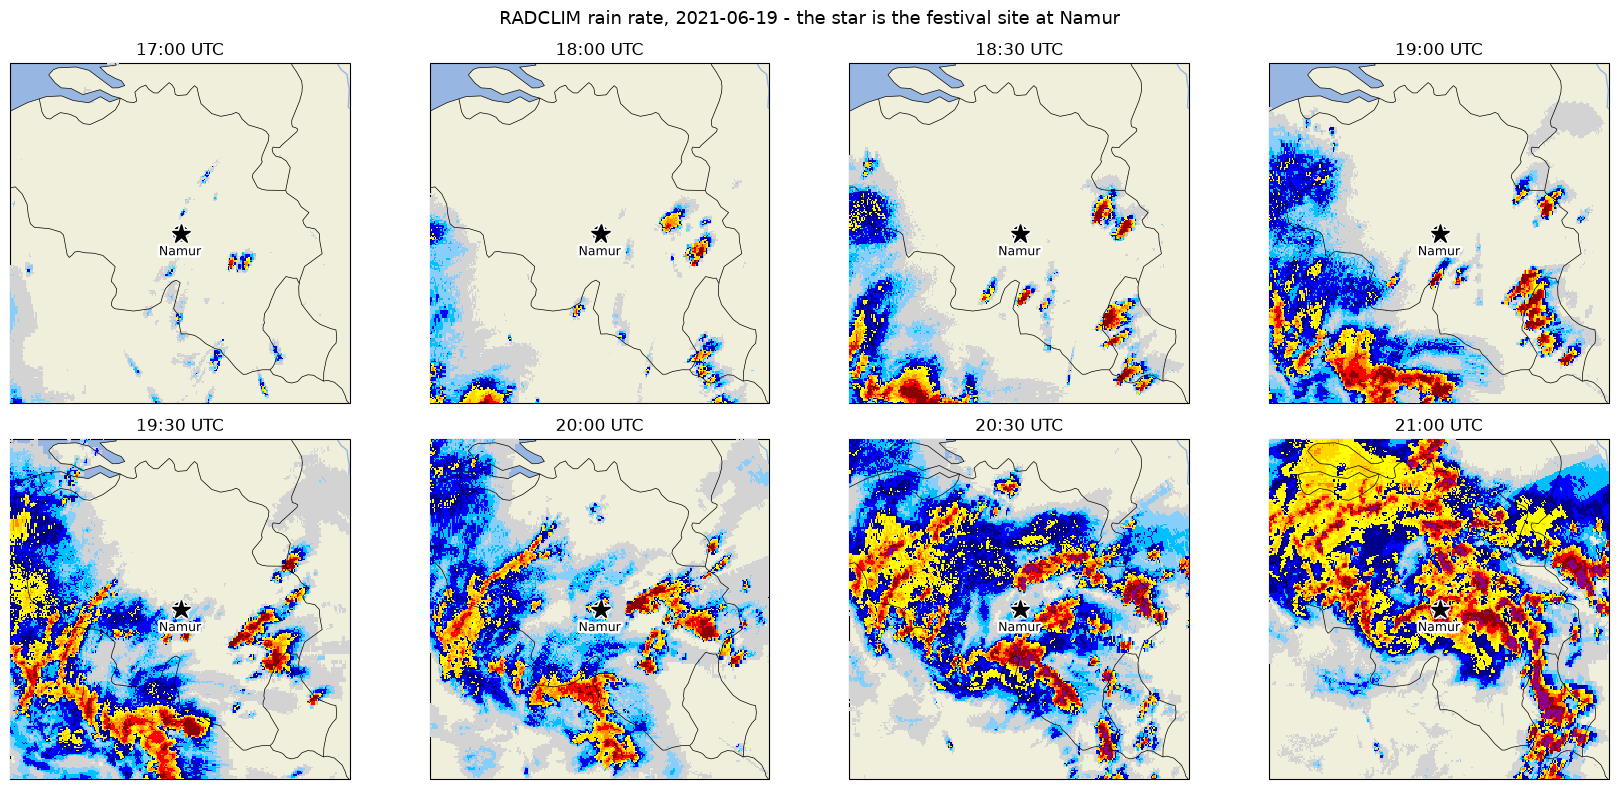

In [7]:
# Eight frames spanning the evening: 17:00 to 21:00 UTC
LOOP_FRAMES = [0, 12, 18, 24, 30, 36, 42, 48]

plt.figure(figsize=(17, 8))
for k, i in enumerate(LOOP_FRAMES):
    ax = site_map((2, 4, k + 1))
    plot_precip_field(precip[i], geodata=metadata, ax=ax,
                      colorscale="STEPS-NL", colorbar=False)
    mark_site(ax)
    ax.set_title(f"{clock(i)} UTC")
plt.suptitle(
    f"RADCLIM rain rate, {EVENT_DAY} - the star is the festival site at {SITE_NAME}",
    fontsize=13)
plt.tight_layout()
plt.show()

### Is the festival a pixel, or a place?

One radar pixel here covers one square kilometre. A festival is not one square kilometre, and a
single pixel is not something a forecast can reasonably be held to.

The cell below asks the same question at four sizes. For each radius, it reports how heavy the
rain is anywhere within that many kilometres of the stage. Watch what happens at both ends of the
range.

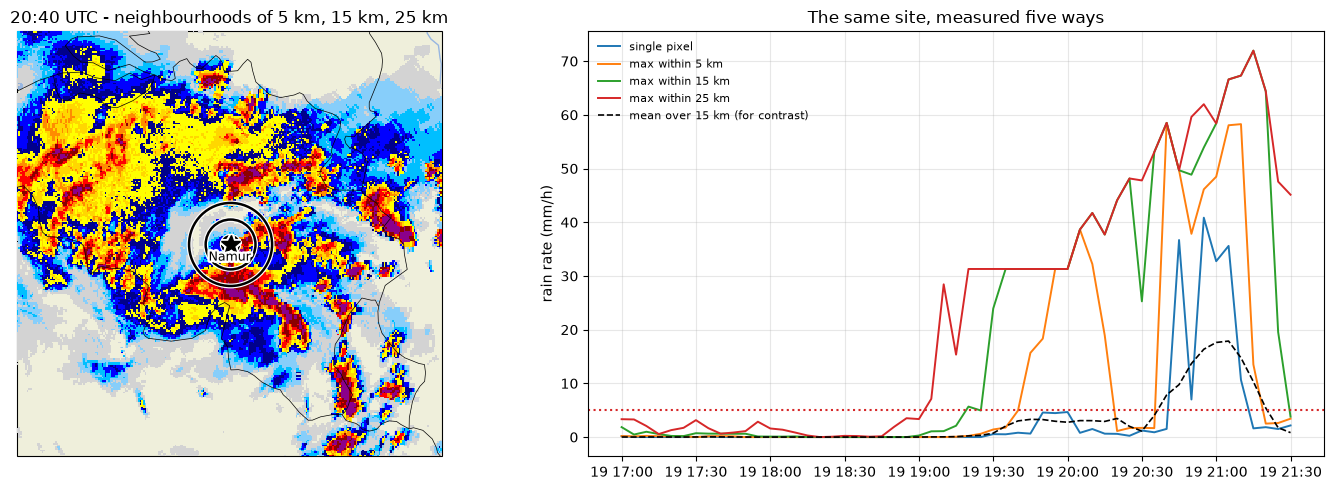

frame-to-frame change (mean |difference| between consecutive frames):
  single pixel             2.9 mm/h   peak  40.9 mm/h
  max within  5 km         4.3 mm/h   peak  58.5 mm/h
  max within 15 km         4.1 mm/h   peak  72.0 mm/h
  max within 25 km         3.2 mm/h   peak  72.0 mm/h
  mean over 15 km          0.8 mm/h   peak  17.9 mm/h


In [8]:
RADII = [0, 5, 15, 25]          # 0 = the single pixel the stage sits in
peak_frame = int(np.argmax([f[disc(5)].max() for f in precip]))

fig = plt.figure(figsize=(15, 5))
ax = site_map((1, 2, 1))
plot_precip_field(precip[peak_frame], geodata=metadata, ax=ax,
                  colorscale="STEPS-NL", colorbar=False)
for r in RADII[1:]:
    mark_site(ax, radius_km=r, label=False)
mark_site(ax, radius_km=0)
ax.set_title(f"{clock(peak_frame)} UTC - neighbourhoods of "
             + ", ".join(f"{r} km" for r in RADII[1:]))

ax2 = fig.add_subplot(1, 2, 2)
for r in RADII:
    ax2.plot(times, site_max(precip, r), lw=1.4,
             label="single pixel" if r == 0 else f"max within {r} km")
ax2.plot(times, site_mean(precip, 15), "k--", lw=1.2,
         label="mean over 15 km (for contrast)")
ax2.axhline(WARN_THR, ls=":", c="tab:red")
ax2.set_ylabel("rain rate (mm/h)")
ax2.set_title("The same site, measured five ways")
ax2.legend(fontsize=8, frameon=False)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("frame-to-frame change (mean |difference| between consecutive frames):")
for r in RADII:
    s = site_max(precip, r)
    name = "single pixel" if r == 0 else f"max within {r:2d} km"
    print(f"  {name:22s} {np.abs(np.diff(s)).mean():5.1f} mm/h   peak {s.max():5.1f} mm/h")
sm = site_mean(precip, 15)
print(f"  {'mean over 15 km':22s} {np.abs(np.diff(sm)).mean():5.1f} mm/h"
      f"   peak {sm.max():5.1f} mm/h")

Three things should now be visible, and together they are the reason this step exists.

The single pixel is unusable. Its value swings by more than 10 mm/h between consecutive five
minute frames. No nowcast can track a signal that jumpy, and no organiser could act on it.

A large neighbourhood is unusable too, for the opposite reason. Widen the circle far enough and
there is always heavy rain somewhere inside it. The answer becomes permanently yes, and a forecast
that always says yes carries no information.

Averaging is the wrong repair for either problem. The dashed line takes the mean over a 15 km
circle, and it sits far below every maximum on the plot. It answers the question "how wet was the
region on average", when the question the panel needs answered is "did it rain hard near the
stage". Take the maximum over a neighbourhood, not the mean.

Somewhere between those two failures lies a radius at which the question is both answerable and
meaningful. Set `NEIGHBOURHOOD_KM` in the setup cell to your choice, then re-run from there.

This is not an artificial exercise. Operational warnings are issued for areas, a municipality or a
river catchment, rather than for grid points, and forecast verification moved the same way for the
same reason. You will meet the verification half of this argument in step 5.

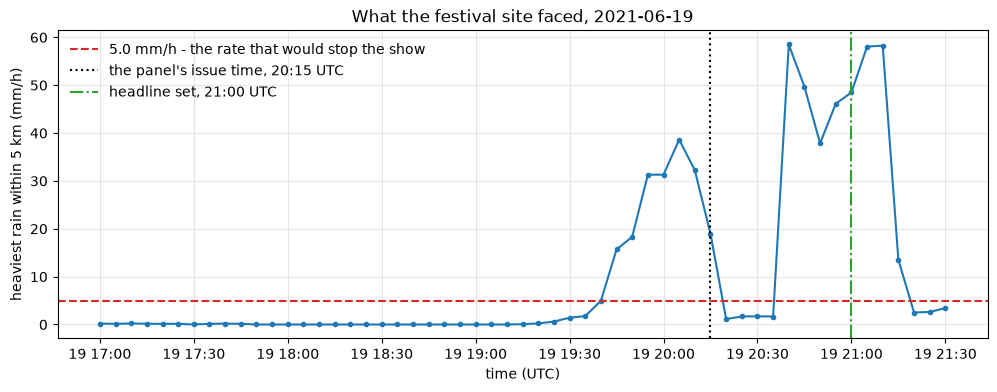

  time     mm/h
 19:00     0.00
 19:05     0.00
 19:10     0.00
 19:15     0.06
 19:20     0.22
 19:25     0.62
 19:30     1.41
 19:35     1.76
 19:40     4.94
 19:45    15.68  <-- above the threshold
 19:50    18.33  <-- above the threshold
 19:55    31.30  <-- above the threshold
 20:00    31.30  <-- above the threshold
 20:05    38.64  <-- above the threshold
 20:10    32.22  <-- above the threshold
 20:15    18.96  <-- above the threshold
 20:20     1.13
 20:25     1.68
 20:30     1.71
 20:35     1.67
 20:40    58.50  <-- above the threshold
 20:45    49.68  <-- above the threshold
 20:50    37.85  <-- above the threshold
 20:55    46.13  <-- above the threshold
 21:00    48.48  <-- above the threshold
 21:05    58.06  <-- above the threshold
 21:10    58.27  <-- above the threshold
 21:15    13.52  <-- above the threshold
 21:20     2.51
 21:25     2.61
 21:30     3.42


In [9]:
# The rain rate at the site through the whole evening, at your chosen neighbourhood
observed_site = site_max(precip)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times, observed_site, "-o", ms=3, color="tab:blue")
ax.axhline(WARN_THR, ls="--", c="tab:red",
           label=f"{WARN_THR} mm/h - the rate that would stop the show")
ax.axvline(np.datetime64(T0), ls=":", c="k", label=f"the panel's issue time, {T0[-5:]} UTC")
ax.axvline(np.datetime64(f"{EVENT_DAY}T21:00"), ls="-.", c="tab:green",
           label="headline set, 21:00 UTC")
ax.set_xlabel("time (UTC)")
ax.set_ylabel(f"heaviest rain within {NEIGHBOURHOOD_KM} km (mm/h)")
ax.set_title(f"What the festival site faced, {EVENT_DAY}")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

print(f"{'time':>6}  {'mm/h':>7}")
for i in range(24, len(times)):
    flag = "  <-- above the threshold" if observed_site[i] > WARN_THR else ""
    print(f"{clock(i):>6}  {observed_site[i]:7.2f}{flag}")

In [10]:
# Select the frames the rest of the notebook works with.
T0_INDEX = int(np.argwhere(times == np.datetime64(T0))[0, 0])

precip_input = precip[T0_INDEX - N_INPUT + 1:T0_INDEX + 1]    # 19:20 .. 20:15
precip_obs = precip[T0_INDEX + 1:T0_INDEX + 1 + N_LEADTIMES]  # 20:20 .. 21:15

print(f"input frames      {clock(T0_INDEX - N_INPUT + 1)} -> {clock(T0_INDEX)} "
      f"({precip_input.shape[0]} frames)")
print(f"verifying against {clock(T0_INDEX + 1)} -> {clock(T0_INDEX + N_LEADTIMES)} "
      f"({precip_obs.shape[0]} frames)")

truth_site = site_max(precip_obs)
print(f"\nafter the issue time, within {NEIGHBOURHOOD_KM} km of the stage: "
      f"{WARN_THR} mm/h reached at {label(first_exceedance(truth_site))}, "
      f"peak {truth_site.max():.1f} mm/h at +{(int(truth_site.argmax()) + 1) * 5} min")

input frames      19:20 -> 20:15 (12 frames)
verifying against 20:20 -> 21:15 (12 frames)

after the issue time, within 5 km of the stage: 5.0 mm/h reached at +25 min, peak 58.5 mm/h at +25 min


### 🔴 VERDICT 1: the ceiling

Here the panel fixes the maximum possible lead time, before any method exists.

Using only the radar loop and the site series above, answer three questions.

**(a)** At what time did rain first exceed `WARN_THR` at the festival site, on the definition of
"at the site" that you chose?

**(b)** Scroll back through the loop. At what time would you first have identified, on the radar
image alone, an echo that threatened this site? Name the frame you would defend to the panel.

**(c)** Subtract the two. State the maximum lead time any radar-based warning could have had. Add
one sentence on what sets that limit.

You have not used a nowcasting method yet. This number is the ceiling on everything that follows.
If a later step gives you less, the shortfall belongs to the method. No method can ever give you
more.

In [11]:
# Write your verdict here, in your own words.
verdict_1 = """
(a) Taking the site as the heaviest rain within 5 km of the stage, the threshold was first
    exceeded at 20:40 UTC. On the single pixel it was 20:45. On a 15 km circle it had already been
    exceeded before the evening started, which is the first sign that the radius is doing real
    work.

(b) On the 18:00 frame there is already a coherent, growing mass of echo about 70 km south of
    Namur. By 18:30 it is unmistakable, roughly 90 km south and expanding fast. It is moving
    north-northeast at the speed the loop shows, so it is pointed at the site. I would defend
    18:00 as the first frame on which a duty forecaster should have flagged it for a site at
    Namur.

(c) The ceiling is 20:40 minus 18:00, which is 2 h 40 min.
    What limits it is not the nowcasting method. It is when the storm first existed on the radar
    at all. No radar-based warning for this site could have had more than about two and a half
    hours of lead time, whatever method we run. Anything less than that was lost somewhere between
    the first echo and the warning. The rest of this review is about finding where.
"""

---
## Background: advection, and the assumption inside it

The simplest possible nowcast does one thing. It takes the last observed rainfall field and moves
it along a motion field, without changing the field as it travels. This is called Lagrangian
persistence, because the pattern persists when you follow it as it moves, even though the rain at
any fixed point on the ground rises and falls. pysteps advects the field with a semi-Lagrangian
scheme, which traces each destination grid cell backwards along the flow to find where its rain
came from.

The assumption inside that is strong, and it is the reason the rest of nowcasting exists. Pure
extrapolation cannot represent growth or decay. A cell that is intensifying keeps the intensity it
had at the issue time, and so does a cell that is dying. The methods that came after plain
extrapolation, S-PROG (Seed, 2003) and STEPS (Bowler et al., 2006), were built precisely to model
the evolution that extrapolation leaves out.

Hold on to that. It explains why this panel's deterministic verdict will turn out wrong in one
particular direction, and it is why step 6 exists.

**Sources.** Seed, A. W. (2003). A dynamic and spatial scaling approach to advection forecasting.
*Journal of Applied Meteorology*, 42(3), 381 to 388,
doi:10.1175/1520-0450(2003)042<0381:ADASSA>2.0.CO;2. Bowler, N. E., Pierce, C. E. and Seed, A. W.
(2006). STEPS: a probabilistic precipitation forecasting scheme which merges an extrapolation
nowcast with downscaled NWP. *Quarterly Journal of the Royal Meteorological Society*, 132(620),
2127 to 2155, doi:10.1256/qj.04.100. Pulkkinen et al. (2019) and the
`pysteps.extrapolation.semilagrangian` API page for the implementation.

## Step 2: the first estimate, motion by eye

Before reaching for an algorithm, do what a forecaster at the desk does. Play the loop from step 1
and read the motion straight off it. The cells have been running in one direction, at one rough
speed, all evening.

Then apply that single vector to the whole domain and advect. Two numbers, 65,536 grid cells, one
hour of forecast.

Look again at the 19:30, 20:00 and 20:30 panels. The box is 256 km across and those panels are
30 minutes apart, so this is a measurement rather than a guess. Which way, and how fast?

In [12]:
# Optical flow and the nowcast models all work on log-transformed rain rates: the
# distribution of rain rate is strongly skewed, and dBR makes the estimation stable.
precip_dbr, metadata_dbr = transformation.dB_transform(
    precip_input, metadata, threshold=0.1, zerovalue=-15.0)
# Lucas-Kanade and VET handle NaNs, DARTS does not, so remove them once, here.
precip_finite = precip_dbr.copy()
precip_finite[~np.isfinite(precip_finite)] = np.nanmin(precip_dbr)

# ---- your estimate, read off the loop ------------------------------------
SPEED_KMH   = 50.0     # how fast are the cells moving?
BEARING_DEG = 0.0      # which way are they heading? 0 = towards north, 90 = east

step_px = SPEED_KMH / 12.0                      # km per 5 min = pixels per time step
u =  step_px * np.sin(np.radians(BEARING_DEG))
v = -step_px * np.cos(np.radians(BEARING_DEG))  # row index increases southward
velocity_eye = np.stack([np.full(precip.shape[1:], u), np.full(precip.shape[1:], v)])
print(f"by eye: {SPEED_KMH:.0f} km/h towards bearing {BEARING_DEG:.0f} deg "
      f"-> u = {u:+.2f}, v = {v:+.2f} pixels per 5 min")

by eye: 50 km/h towards bearing 0 deg -> u = +0.00, v = -4.17 pixels per 5 min


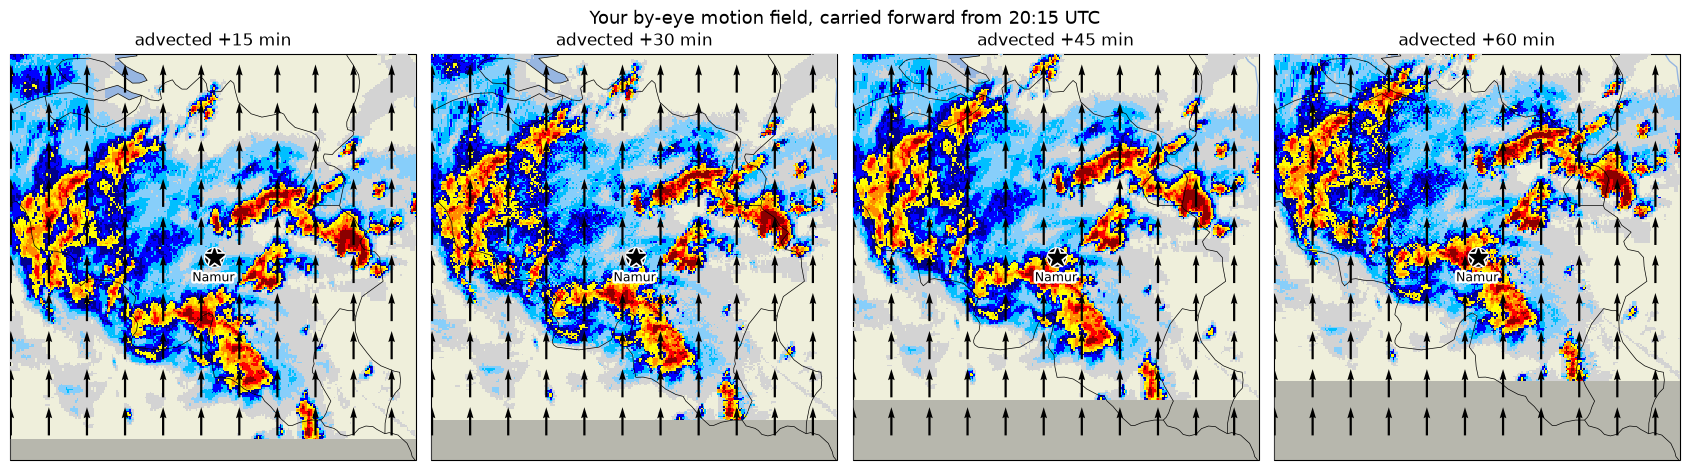

this nowcast puts 5.0 mm/h within 5 km of the stage at +35 min, peaking at 37.7 mm/h


In [13]:
# Lagrangian persistence: carry the last observed field along the motion field
nowcast_method = nowcasts.get_method("extrapolation")


def advect(velocity):
    """Extrapolate the last observed field along a motion field, in mm/h."""
    out = nowcast_method(precip_finite[-1], velocity, timesteps=N_LEADTIMES,
                         extrap_kwargs={"allow_nonfinite_values": False})
    return transformation.dB_transform(out, metadata_dbr, inverse=True)[0]


nowcast_eye = advect(velocity_eye)

plt.figure(figsize=(17, 4.8))
for k, j in enumerate(range(2, 13, 3)):          # +15, +30, +45, +60 min
    ax = site_map((1, 4, k + 1))
    plot_precip_field(nowcast_eye[j], geodata=metadata, ax=ax,
                      colorscale="STEPS-NL", colorbar=False)
    quiver(velocity_eye, geodata=metadata, ax=ax, step=24, quiver_kwargs={"scale": 60})
    mark_site(ax)
    ax.set_title(f"advected +{(j + 1) * 5} min")
plt.suptitle(f"Your by-eye motion field, carried forward from {T0[-5:]} UTC", fontsize=13)
plt.tight_layout()
plt.show()

eye_site = site_max(nowcast_eye)
print(f"this nowcast puts {WARN_THR} mm/h within {NEIGHBOURHOOD_KM} km of the stage at "
      f"{label(first_exceedance(eye_site))}, peaking at {eye_site.max():.1f} mm/h")

### 🟠 COMMITMENT A: naming the debt

This is not a verdict. State what your answer currently rests on.

You have just forecast an hour of rain over a festival using two numbers you read off a screen.
Write one sentence you would be willing to say out loud in the review. What does this nowcast
assume, and what evidence do you have that your motion estimate is right?

If the honest answer to the second half is "none", write `none`. That is the correct answer at
this point, and it is the reason step 3 exists.

In [14]:
# One sentence. If the honest answer is 'none', write none.
commitment_a = """
It assumes that one speed and one direction, read by eye off a loop, describe the motion of every
one of the 65,536 grid cells in the domain. It assumes this stays true for a full hour. It also
assumes the rain neither grows nor decays while it travels. Evidence that the estimate is right:
none. I checked it against nothing. It produces a plausible answer, but a wrong vector would also
produce a plausible answer, and I currently have no way of telling those two cases apart.
"""

---
## Background: three ways to measure motion

Step 2 asked you for one vector, estimated by eye. An algorithm can do better. It can estimate a
vector at every grid cell. The family of algorithms that does this is called optical flow, and the
three that pysteps offers reach the answer by three different routes.

**Lucas-Kanade** is a sparse feature tracker rather than a true optical flow method. It first
picks out points where the image has a large gradient, meaning the corners and edges of rainfall
features. It estimates a displacement for each of those points. It then interpolates between them
to fill a smooth field across the whole domain. pysteps builds on the pyramidal implementation
described by Bouguet (2001), which repeats the search at several image resolutions in turn, so
that displacements too large to find at full resolution are still recovered.

**VET**, short for variational echo tracking, does not track features at all. It solves for the
displacement field over the entire domain at once, by minimising a cost function that rewards
matching the two images and penalises a rough field. Laroche and Zawadzki (1995) introduced this
approach for radar data. Solving over the whole domain costs far more computer time than tracking
a few hundred points, and it returns a smoother field.

**DARTS** works in the Fourier domain. Ruzanski et al. (2011) wrote the advection equation in
terms of spectral coefficients, so the motion is recovered by solving a linear system rather than
by matching images in space. This lets you choose how many wavenumbers to keep, and therefore
which spatial scales the motion is fitted to. The cost is that a small number of coefficients
cannot describe a complicated field. Watch the DARTS panel for rotation in areas that contain no
rain at all, which is the signature of that limitation.

Each method also has its own appetite for input frames. VET takes two or three fields. DARTS needs
strictly more frames than its `N_t` coefficient, which defaults to 4, and it fits motion through a
time series, so it does best when given a long one. Lucas-Kanade works from a handful.

**Sources.** Bouguet, J.-Y. (2001). *Pyramidal implementation of the affine Lucas Kanade feature
tracker: description of the algorithm.* Intel Corporation. Laroche, S. and Zawadzki, I. (1995).
Retrievals of horizontal winds from single-Doppler clear-air data by methods of cross correlation
and variational analysis. *Journal of Atmospheric and Oceanic Technology*, 12(4), 721 to 738,
doi:10.1175/1520-0426(1995)012<0721:ROHWFS>2.0.CO;2. Ruzanski, E., Chandrasekar, V. and Wang, Y.
(2011). The CASA nowcasting system. *Journal of Atmospheric and Oceanic Technology*, 28(5), 640 to
655, doi:10.1175/2011JTECHA1496.1. The `pysteps.motion` API pages for the implementations, and the
`pysteps.motion.darts.DARTS` docstring for `N_t`.

## Step 3: compute the optical flow three ways

A review panel must be able to say why it trusted its inputs. Reproduce the motion field three
ways, time each one, and look at the vectors over the festival area.

You decide how many of your twelve input frames each method receives.

LK     used  4 frames and took   0.527 seconds


VET    used  3 frames and took  26.239 seconds


DARTS  used 12 frames and took   3.162 seconds


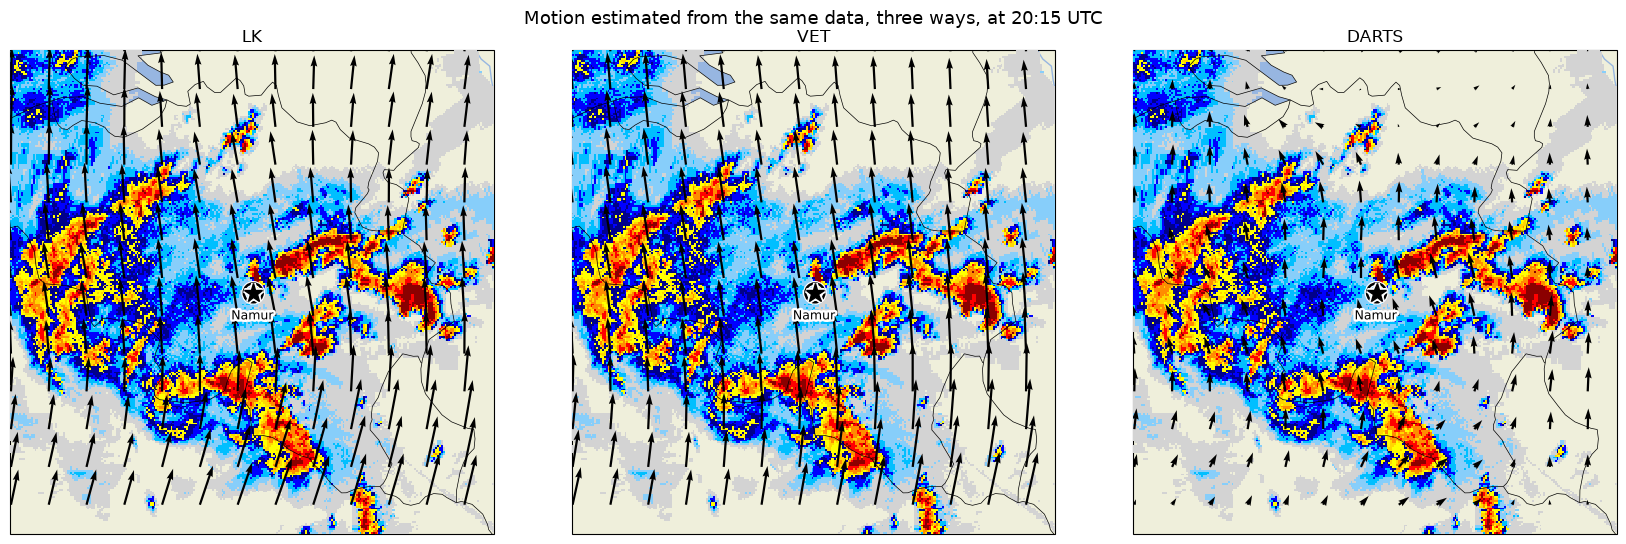

In [15]:
methods = ["LK", "VET", "DARTS"]
velocities = {}

plt.figure(figsize=(17, 5.5))
for k, method in enumerate(methods):
    oflow = motion.get_method(method)

    if method == "LK":
        frames = precip_finite[-4:]
    elif method == "VET":
        frames = precip_finite[-3:]
    elif method == "DARTS":
        frames = precip_finite

    starttime = time.time()
    velocities[method] = oflow(frames, verbose=False)
    runtime = time.time() - starttime
    print(f"{method:6s} used {frames.shape[0]:2d} frames and took {runtime:7.03f} seconds")

    ax = site_map((1, 3, k + 1))
    # the background is the last observed field, the one all three flows end on
    plot_precip_field(precip_input[-1], geodata=metadata, ax=ax,
                      colorscale="STEPS-NL", colorbar=False)
    # step = arrow spacing in grid cells, scale = arrow length (larger = shorter).
    # Keep scale identical across the panels or they cannot be compared.
    quiver(velocities[method], geodata=metadata, ax=ax, step=20,
           quiver_kwargs={"scale": 60})
    mark_site(ax)
    ax.set_title(method)
plt.suptitle(f"Motion estimated from the same data, three ways, at {T0[-5:]} UTC", fontsize=13)
plt.tight_layout()
plt.show()

In [16]:
# The arrows are one thing. What each field would have told the festival is another.
head = f"reaches {WARN_THR} mm/h"
print(f"{'field':12s} | {'mean speed':>22s} | {head:>22s} | peak")
print("-" * 78)
for name, vf in [("by eye", velocity_eye)] + list(velocities.items()):
    s = site_max(advect(vf))
    speed = np.hypot(vf[0], vf[1]).mean()
    print(f"{name:12s} | {speed:5.2f} px/5min ({speed * 1000 / 300:4.1f} m/s) | "
          f"{label(first_exceedance(s)):>22s} | {s.max():5.1f} mm/h")
print("-" * 78)
print(f"{'TRUTH':12s} | {'':>22s} | {label(first_exceedance(truth_site)):>22s} | "
      f"{truth_site.max():5.1f} mm/h")

field        |             mean speed |       reaches 5.0 mm/h | peak
------------------------------------------------------------------------------


by eye       |  4.17 px/5min (13.9 m/s) |                +35 min |  37.7 mm/h


LK           |  4.90 px/5min (16.3 m/s) |                +30 min |  28.8 mm/h


VET          |  4.84 px/5min (16.1 m/s) |                +30 min |  32.5 mm/h


DARTS        |  1.82 px/5min ( 6.1 m/s) |    not within the hour |   1.8 mm/h
------------------------------------------------------------------------------
TRUTH        |                        |                +25 min |  58.5 mm/h


### 🔴 VERDICT 2: the defended input

Commit this in writing before you see any verification score.

Put your name to one of the fields, and answer three questions.

**(a)** Which motion field goes in the panel's report?

**(b)** Justify it by a property of the field itself, not by its runtime. Say where its vectors
are defined, whether it rotates where there is no rain, and how it behaves over the festival site.

**(c)** You now know what each method costs. If operations needed a new field every five minutes,
which of these could you actually run? Does that change your answer to (a)?

Do not edit this answer later. Its value to the panel lies precisely in having been written before
the scores were seen.

In [17]:
# Commit before you scroll on. Do not edit this later.
verdict_2_motion = """
(a) Lucas-Kanade.

(b) LK and VET agree closely. Both give a broadly uniform north-northeastward field at about
    4.9 pixels per 5 minutes, roughly 16 m/s, with vectors over the festival site pointing
    straight at it from the south. Agreement between two methods that work in completely different
    ways, a sparse feature tracker and a whole-domain variational solve, is the strongest evidence
    available at this point. It also broadly vindicates the by-eye estimate, which was slower but
    pointed the same way. DARTS disagrees badly. Its field is under 2 pixels per 5 minutes, well
    under half the speed, and it puts curl into parts of the domain that contain no rain at all,
    which is the spectral-fit artefact we were warned to look for. A field that slow cannot bring
    the southern echo to Namur within the hour, and its nowcast never reaches the threshold at the
    site at all. I would not sign a report built on it.

(c) VET took roughly 35 seconds against 0.6 for LK, on a domain of only 256 x 256 km. Scaled to
    the operational 700 x 700 km composite and repeated every 5 minutes, VET is the awkward one,
    LK is comfortable, and DARTS is affordable but wrong here. So cost does not change my answer.
    The cheapest method is also the one I would defend on its merits, which is a convenient
    outcome rather than a principled one, and I would say so in the report.
"""

---
## Background: two frames, or more?

One more choice hides inside every motion estimate. How much history should the estimate use?

The classical formulation of optical flow compares exactly two images. Nothing forces you to stop
there. If the motion is steady, an estimate made across several frames averages out the noise in
any single pair, and it should be steadier as a result. pysteps allows extra frames for
Lucas-Kanade, and DARTS requires them by construction, because it fits motion through a time
series rather than between one pair.

That is the argument for using more history. It is worth testing rather than believing, and the
next cell tests it on this case.

**Sources.** Bouguet (2001) and Ruzanski et al. (2011) for the two formulations. The
`pysteps.motion` API pages document which methods accept more than two input fields.

## Step 4: two frames against three

Uncertainty enters the review here, and it enters from the method rather than from the atmosphere.
Estimate the motion from the fewest images the method accepts. Then estimate it again from one
more image. Compare what arrives over the festival under each.

In [18]:
oflow = motion.get_method("LK")

velocity_2frame = oflow(precip_finite[-2:], verbose=False)
velocity_3frame = oflow(precip_finite[-3:], verbose=False)

for name, vf in [("2 frames", velocity_2frame), ("3 frames", velocity_3frame)]:
    s = site_max(advect(vf))
    speed = np.hypot(vf[0], vf[1]).mean()
    print(f"{name} | mean speed {speed:5.2f} px/5min | "
          f"{WARN_THR} mm/h at the site at {label(first_exceedance(s))} | "
          f"peak {s.max():5.1f} mm/h")

2 frames | mean speed  4.90 px/5min | 5.0 mm/h at the site at +30 min | peak  30.5 mm/h


3 frames | mean speed  4.94 px/5min | 5.0 mm/h at the site at +30 min | peak  36.3 mm/h


### 🟠 COMMITMENT B: uncertainty from the method

This is not a verdict. Confront an answer that moves when you change a choice.

**(a)** How many minutes apart are the two arrival times over the site?

**(b)** Compare that with how far the answer moved between Lucas-Kanade and DARTS in step 3, and
with how far it moved between your by-eye field and Lucas-Kanade in step 2. Which choice dominates
on this case, the amount of history or the method?

**(c)** Does the disagreement you just measured belong in the review as an error bar, or as a
footnote? Answer in one sentence, and commit to one of the two.

In [19]:
# Commit to one: error bar, or footnote.
commitment_b = """
(a) Zero. Both give the threshold at the same lead time, and they peak within a few tenths of a
    mm/h of each other. The mean speeds differ by less than 1%. At 5-minute output I cannot
    resolve any difference at all.

(b) The method dominates, and not narrowly. Frame count moved the answer by less than one output
    step. LK against DARTS was the difference between a warning and no warning whatsoever, and
    even the by-eye field moved the arrival time by two output steps. The textbook expectation is
    that temporal smoothing stabilises the estimate. Here the estimate was already stable, so the
    smoothing had nothing to do.

(c) A footnote. The honest error bar on this forecast does not come from the number of frames, and
    quoting a zero-minute spread would tell the panel the answer is far more certain than it is.
    Where the real uncertainty lives is still an open question at this point in the review.
"""

---
## Background: verifying a deterministic nowcast

A nowcast is worth only what you can demonstrate about it. pysteps splits deterministic
verification across three submodules. `detcatscores` holds categorical scores, computed after
turning each field into a yes or no event at a rain rate threshold. `detcontscores` holds
continuous scores, computed on the rain rates themselves. `spatialscores` holds the scale-aware
family you will meet shortly.

Three scores appear below, all evaluated at your `WARN_THR`.

- **POD**, the probability of detection. Of all the places where it really did rain that hard,
  what fraction did the nowcast catch? A perfect forecast scores 1.
- **FAR**, the false alarm ratio. Of all the places where the nowcast said it would rain that
  hard, what fraction stayed below the threshold? A perfect forecast scores 0.
- **ME**, the mean error. This is the bias, in mm/h. A negative value means the nowcast is
  systematically too dry.

Read POD and FAR together, never separately. A forecast of heavy rain everywhere scores a perfect
POD while being useless.

**Sources.** The `pysteps.verification.detcatscores.det_cat_fct` and
`pysteps.verification.detcontscores.det_cont_fct` docstrings, which list and define every
available score. Ebert, E., Wilson, L., Weigel, A., Mittermaier, M., Nurmi, P., Gill, P.,
Göber, M., Joslyn, S., Brown, B., Fowler, T. and Watkins, A. (2013). Progress and challenges in
forecast verification. *Meteorological Applications*, 20(2), 130 to 139, doi:10.1002/met.1392,
review what scores of this kind can and cannot tell you.

## Step 5: the deterministic nowcast, and verdict two

Run the extrapolation nowcast for twelve lead times, using the field you defended in step 3. Then
verify it against what actually happened.

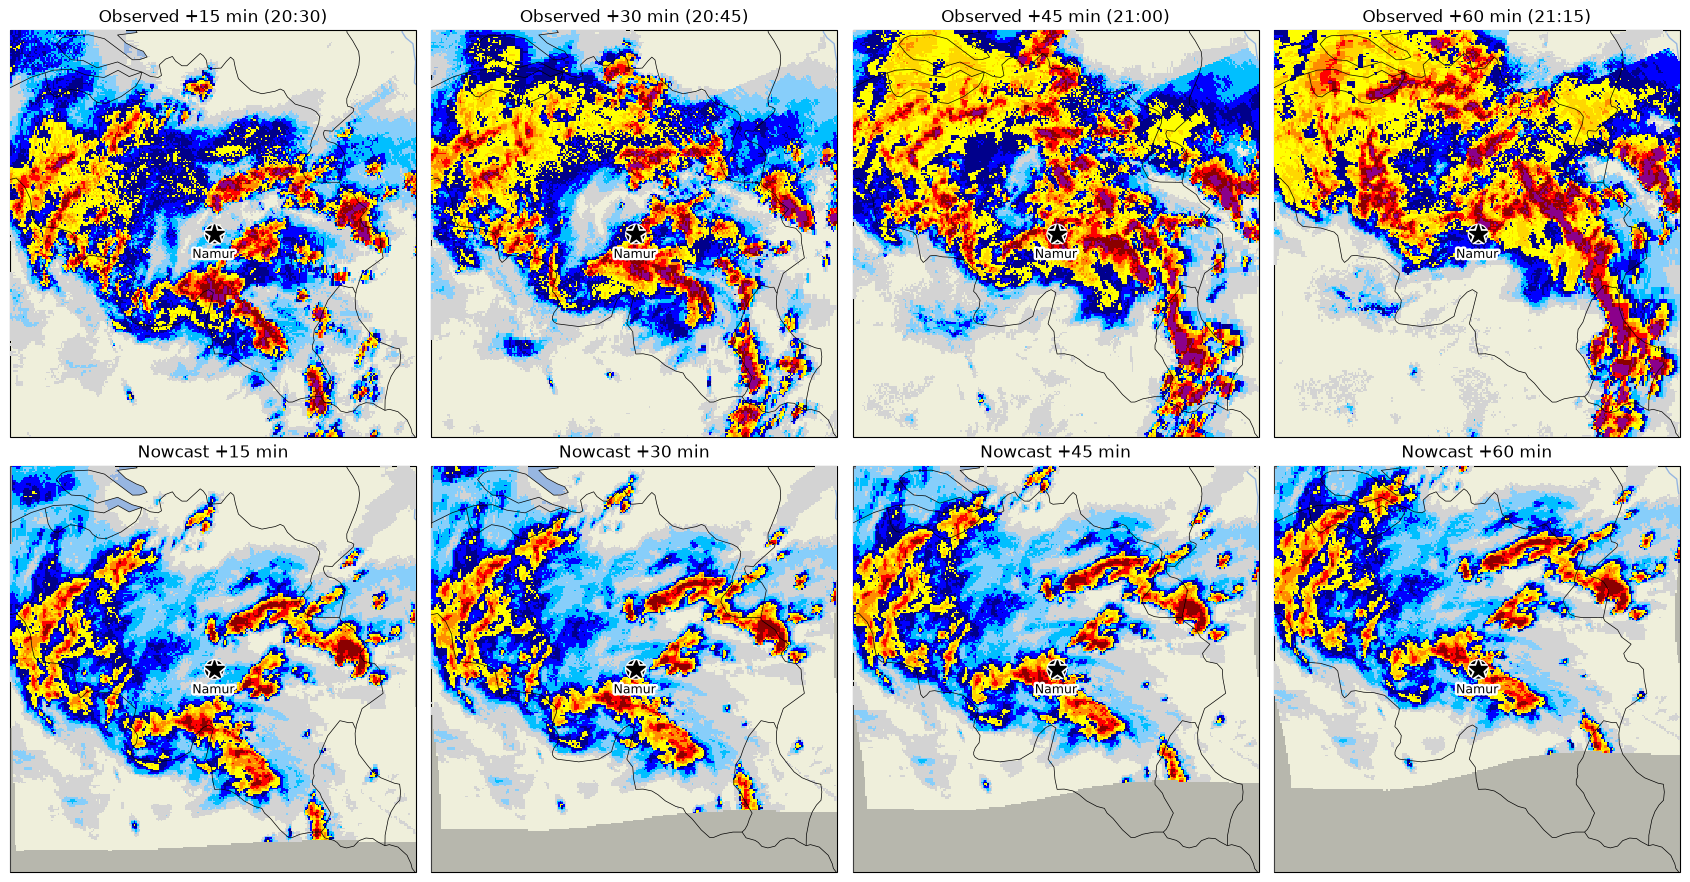

In [20]:
velocity = velocities["LK"]

nowcast_det = advect(velocity)

plt.figure(figsize=(17, 9))
for k, j in enumerate(range(2, 13, 3)):
    ax = site_map((2, 4, k + 1))
    plot_precip_field(precip_obs[j], geodata=metadata, ax=ax,
                      colorscale="STEPS-NL", colorbar=False)
    mark_site(ax)
    ax.set_title(f"Observed +{(j + 1) * 5} min ({clock(T0_INDEX + j + 1)})")
for k, j in enumerate(range(2, 13, 3)):
    ax = site_map((2, 4, 5 + k))
    plot_precip_field(nowcast_det[j], geodata=metadata, ax=ax,
                      colorscale="STEPS-NL", colorbar=False)
    mark_site(ax)
    ax.set_title(f"Nowcast +{(j + 1) * 5} min")
plt.tight_layout()
plt.show()

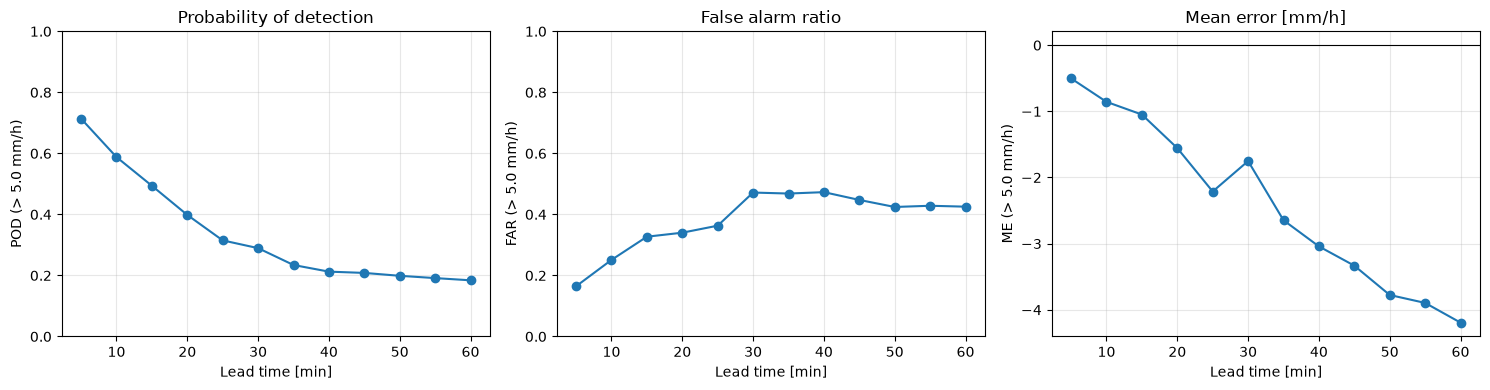

In [21]:
from collections import defaultdict

cat_scores, cont_scores = ["POD", "FAR"], ["ME"]
scores = defaultdict(list)

for i in range(N_LEADTIMES):
    cat = verification.detcatscores.det_cat_fct(
        nowcast_det[i], precip_obs[i], thr=WARN_THR, scores=cat_scores)
    cont = verification.detcontscores.det_cont_fct(
        nowcast_det[i], precip_obs[i], scores=cont_scores)
    for name in cat_scores:
        scores[name].append(cat[name])
    for name in cont_scores:
        scores[name].append(cont[name])

lead = np.arange(1, N_LEADTIMES + 1) * metadata["accutime"]

plt.figure(figsize=(15, 4))
for k, (name, title, ylim) in enumerate([
    ("POD", "Probability of detection", (0, 1)),
    ("FAR", "False alarm ratio", (0, 1)),
    ("ME", "Mean error [mm/h]", None),
]):
    plt.subplot(1, 3, k + 1)
    plt.plot(lead, scores[name], "o-")
    if ylim:
        plt.ylim(ylim)
    else:
        plt.axhline(0, c="k", lw=0.8)
    plt.xlabel("Lead time [min]")
    plt.ylabel(f"{name} (> {WARN_THR} mm/h)")
    plt.title(title)
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Background: the double penalty, and verifying at a scale

Every score above compares one pixel in the forecast with the same pixel in the observations. For
convective rain that is close to the harshest test you can devise.

Consider a nowcast that puts a thunderstorm cell five kilometres from where it actually landed.
Pixel-wise scoring counts that one mistake twice. It counts once as a miss, at the place where
rain fell and none was forecast. It counts again as a false alarm, at the place where rain was
forecast and none fell. A forecaster looking at the two images side by side would call it a good
forecast. This is the double penalty, and it creates a perverse incentive. Blurring a forecast
improves the score, while sharpening it makes the score worse.

You met this problem from the other end in step 1, and the answer is the same. Verify over a
neighbourhood rather than over a pixel. Roberts and Lean (2008) introduced the Fractions Skill
Score to do exactly that. It slides a window across both fields. Inside each window it computes
the fraction of pixels above the threshold, in the forecast and in the observations, and compares
the two fractions. In pysteps the `scale` argument sets the size of that moving window in pixels,
which is kilometres on this grid.

There is a deeper reason to expect the scale to matter. Predictability is itself scale-dependent.
Germann and Zawadzki (2002) measured how quickly radar rainfall patterns lose their correlation
with themselves once you follow them along the flow, and found that predictability increases with
spatial scale. Large patterns stay recognisable far longer than small ones. That result is why
S-PROG and STEPS decompose the field into a spatial cascade and treat each scale differently
(Seed, 2003; Bowler et al., 2006). Asking a nowcast for a one-kilometre answer at +60 minutes is
asking it for the part that decorrelates first.

Choose the neighbourhood sizes at which the panel is willing to be judged.

**Sources.** Roberts, N. M. and Lean, H. W. (2008). Scale-selective verification of rainfall
accumulations from high-resolution forecasts of convective events. *Monthly Weather Review*,
136(1), 78 to 97, doi:10.1175/2007MWR2123.1, which pysteps cites for the FSS. Ebert et al. (2013)
for neighbourhood verification more broadly. Germann, U. and Zawadzki, I. (2002).
Scale-dependence of the predictability of precipitation from continental radar images. Part I:
description of the methodology. *Monthly Weather Review*, 130(12), 2859 to 2873,
doi:10.1175/1520-0493(2002)130<2859:SDOTPO>2.0.CO;2. Seed (2003) and Bowler et al. (2006) for the
cascade. The `pysteps.verification.spatialscores.fss` docstring for the `scale` argument.

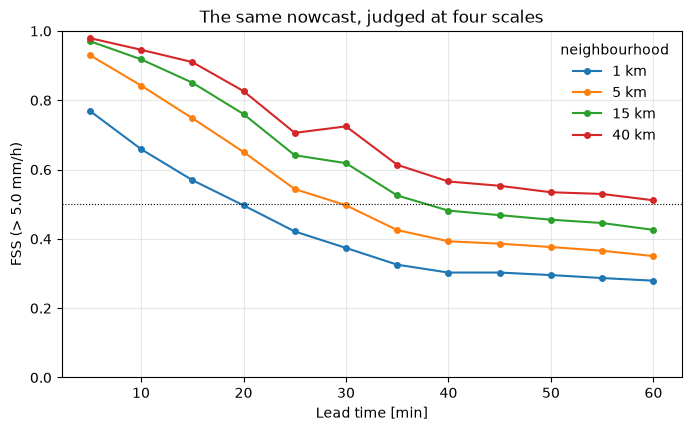

lead time at which FSS drops below 0.5:
   1 km neighbourhood: +15 min
   5 km neighbourhood: +25 min
  15 km neighbourhood: +35 min
  40 km neighbourhood: still above 0.5 at +60 min


In [22]:
FSS_SCALES = [1, 5, 15, 40]        # neighbourhood sizes in km (= pixels here)

fss = verification.get_method("FSS")
fss_curves = {s: [fss(nowcast_det[i], precip_obs[i], thr=WARN_THR, scale=s)
                  for i in range(N_LEADTIMES)] for s in FSS_SCALES}

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in FSS_SCALES:
    ax.plot(lead, fss_curves[s], "o-", ms=4, label=f"{s} km")
ax.axhline(0.5, c="k", lw=0.8, ls=":")
ax.set_xlabel("Lead time [min]")
ax.set_ylabel(f"FSS (> {WARN_THR} mm/h)")
ax.set_title("The same nowcast, judged at four scales")
ax.set_ylim(0, 1)
ax.legend(title="neighbourhood", frameon=False)
ax.grid(alpha=0.3)
plt.show()

print("lead time at which FSS drops below 0.5:")
for s in FSS_SCALES:
    below = [i for i, f in enumerate(fss_curves[s]) if f < 0.5]
    when = f"+{below[0] * 5} min" if below else "still above 0.5 at +60 min"
    print(f"  {s:2d} km neighbourhood: {when}")

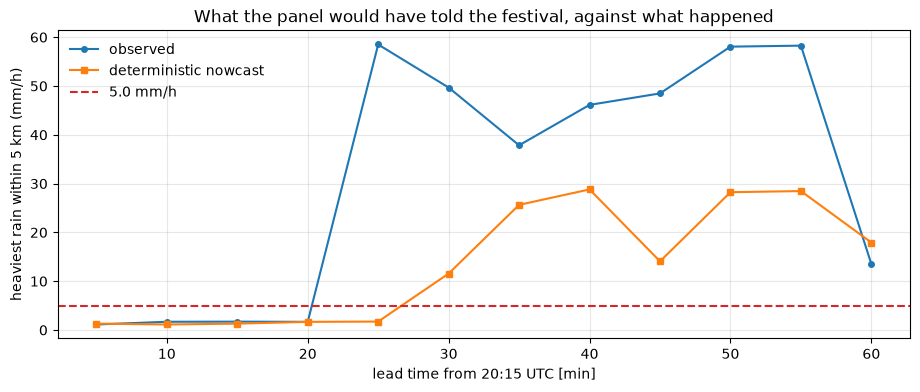

nowcast reaches 5.0 mm/h at +30 min, peaking at 28.8 mm/h
observed        5.0 mm/h at +25 min, peaking at 58.5 mm/h
  +  5 min | POD 0.71 | FAR 0.16 | ME  -0.50 mm/h
  + 10 min | POD 0.59 | FAR 0.25 | ME  -0.86 mm/h
  + 15 min | POD 0.49 | FAR 0.33 | ME  -1.05 mm/h
  + 20 min | POD 0.40 | FAR 0.34 | ME  -1.56 mm/h
  + 25 min | POD 0.31 | FAR 0.36 | ME  -2.21 mm/h
  + 30 min | POD 0.29 | FAR 0.47 | ME  -1.75 mm/h
  + 35 min | POD 0.23 | FAR 0.47 | ME  -2.65 mm/h
  + 40 min | POD 0.21 | FAR 0.47 | ME  -3.04 mm/h
  + 45 min | POD 0.21 | FAR 0.45 | ME  -3.33 mm/h
  + 50 min | POD 0.20 | FAR 0.42 | ME  -3.78 mm/h
  + 55 min | POD 0.19 | FAR 0.43 | ME  -3.90 mm/h
  + 60 min | POD 0.18 | FAR 0.43 | ME  -4.19 mm/h


In [23]:
# And the only series the festival organiser would have cared about
det_site = site_max(nowcast_det)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(lead, truth_site, "-o", ms=4, label="observed", color="tab:blue")
ax.plot(lead, det_site, "-s", ms=4, label="deterministic nowcast", color="tab:orange")
ax.axhline(WARN_THR, ls="--", c="tab:red", label=f"{WARN_THR} mm/h")
ax.set_xlabel(f"lead time from {T0[-5:]} UTC [min]")
ax.set_ylabel(f"heaviest rain within {NEIGHBOURHOOD_KM} km (mm/h)")
ax.set_title("What the panel would have told the festival, against what happened")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

print(f"nowcast reaches {WARN_THR} mm/h at {label(first_exceedance(det_site))}, "
      f"peaking at {det_site.max():.1f} mm/h")
print(f"observed        {WARN_THR} mm/h at {label(first_exceedance(truth_site))}, "
      f"peaking at {truth_site.max():.1f} mm/h")
for i, m in enumerate(lead):
    print(f"  +{int(m):3d} min | POD {scores['POD'][i]:.2f} | FAR {scores['FAR'][i]:.2f}"
          f" | ME {scores['ME'][i]:6.2f} mm/h")

### 🔴 VERDICT 3: the deterministic warning

This is the second of the three verdicts.

State it as a single sentence in this form:

> "A warning for the festival site could have been issued at HH:MM, for rain exceeding X mm/h
> within Y km of the stage, arriving at HH:MM, a lead time of N minutes."

Then answer four questions, using your own scores.

**(a)** At that lead time, what were POD and FAR?

**(b)** For how long was this nowcast skilful at one kilometre, and for how long at your chosen
neighbourhood? Which of those two numbers belongs in the report, and why?

**(c)** Your mean error is negative and it grows with lead time. What does the nowcast
systematically fail to do? Why can advection alone never do it?

**(d)** The organiser asks the only two questions they actually care about. How likely is it, and
how heavy will it be? Write, word for word, the most you can honestly say using only this
nowcast.

In [24]:
# One sentence in the given form, then (a)-(d).
verdict_deterministic = """
"A warning for the festival site could have been issued at 20:15 UTC, for rain exceeding 5 mm/h
within 5 km of the stage, arriving at 20:45 UTC, a lead time of 30 minutes."

(a) At +30 min, POD was 0.29 and FAR was 0.47.

(b) At 1 km the nowcast fell below an FSS of 0.5 by +25 min. At 5 km it held to +35 min, and at
    40 km it never dropped below 0.5 within the hour. The 5 km number is the one that belongs in
    the report, because 5 km is the scale the warning is actually written at. Quoting the 1 km
    figure would understate the forecast. Quoting the 40 km figure would flatter it, because at
    that size the question has stopped being about this festival.

(c) It fails to intensify. The observed peak within 5 km of the stage was 58 mm/h. The nowcast
    peaked at 29, half of that, and the mean error runs steadily more negative with lead time.
    Advection carries the pattern it was given and can do nothing else. Representing growth and
    decay is exactly what S-PROG and STEPS were built to add, and this nowcast has neither. The
    system was still deepening as it crossed the Sambre, and no improvement to the motion estimate
    could have recovered that.

(d) "Rain exceeding 5 mm/h will reach the area around the site at about 20:45."
    That is the whole of it. I cannot attach a likelihood to it. I cannot say how heavy it will
    get, and I know from (c) that whatever intensity I quote will be too low. With a false alarm
    ratio near one in two I also cannot tell the organiser whether this particular warning is one
    of the wrong ones. They have to decide whether to clear a field of people on a bare yes.
"""

---
## Background: from one future to many

A deterministic nowcast hands the organiser one plausible future and presents it as the only one.
An ensemble replaces that single future with a set of forecasts. Each member is one possible
outcome, and the members differ from each other in ways chosen to represent what you do not know.

STEPS, described by Bowler et al. (2006) and built on the scaling approach of Seed (2003), does
this in a specific way. It decomposes each field into a spatial cascade using a Fourier transform,
splitting it into levels that each hold one band of spatial scales. It then evolves each level
with its own autoregressive model, meaning each level is predicted from its own recent past, with
weights fitted to how quickly that particular scale decorrelates. The large scales carry forward
almost unchanged. The small scales lose their memory quickly, and where the model has no skill
left, STEPS replaces the signal with spatially correlated random noise. That noise is what makes
one member differ from another, and it is how the ensemble represents growth and decay.

Do not hand the ensemble mean to a decision maker. Averaging the members cancels out the detail
they disagree about, and what they disagree about is exactly the position of the intense
convective cells. The result is a smooth field that no single member resembles and no atmosphere
would produce. The same loss of variance is why S-PROG, which forecasts only the predictable part
of the signal, returns a field that grows smoother as lead time increases (Seed, 2003).

What you give the decision maker instead is an exceedance probability, meaning the fraction of
members in which the rain crosses a chosen threshold. Germann and Zawadzki (2004) set out how to
turn radar extrapolation into probability forecasts of this kind.

**Sources.** Bowler, N. E., Pierce, C. E. and Seed, A. W. (2006). STEPS: a probabilistic
precipitation forecasting scheme which merges an extrapolation nowcast with downscaled NWP.
*Quarterly Journal of the Royal Meteorological Society*, 132(620), 2127 to 2155,
doi:10.1256/qj.04.100. Seed (2003) for the cascade and the scaling argument. Germann, U. and
Zawadzki, I. (2004). Scale-dependence of the predictability of precipitation from continental
radar images. Part II: probability forecasts. *Journal of Applied Meteorology*, 43(1), 74 to 89,
doi:10.1175/1520-0450(2004)043<0074:SDOTPO>2.0.CO;2. Pulkkinen et al. (2019) for the pysteps
implementation. STEPS prints its cascade correlations and autoregression parameters as it runs, so
expect a long block of output below.

## Step 6: the probabilistic nowcast, and the final verdict

Run the ensemble. Look at the mean beside two individual members. Then compute the number the
organiser actually needed, which is the probability that rain exceeds `WARN_THR` anywhere within
your neighbourhood, at each lead time.

In [25]:
n_ens_members = 20
seed = 1234        # fixed so the notebook is reproducible

nowcast_ens = nowcasts.get_method("steps")(
    precip_finite[-3:], velocity, timesteps=N_LEADTIMES,
    n_ens_members=n_ens_members,
    n_cascade_levels=8,
    precip_thr=metadata_dbr["threshold"],
    kmperpixel=metadata_dbr["xpixelsize"] / 1000.0,
    timestep=metadata_dbr["accutime"],
    noise_method="nonparametric",
    vel_pert_method="bps",
    probmatching_method="cdf",
    mask_method="incremental",
    seed=seed,
    num_workers=4,
)
nowcast_ens = transformation.dB_transform(nowcast_ens, metadata_dbr, inverse=True)[0]
print(f"\nensemble: {nowcast_ens.shape}  (members, lead times, y, x)")

Inputs validated and initialized successfully.
Computing STEPS nowcast
-----------------------

Inputs
------
input dimensions: 256x256
km/pixel:         1.0000000000001164
time step:        5.0 minutes

Methods
-------
extrapolation:          semilagrangian
bandpass filter:        gaussian
decomposition:          fft
noise generator:        nonparametric
noise adjustment:       no
velocity perturbator:   bps
conditional statistics: no
precip. mask method:    incremental
probability matching:   cdf
FFT method:             numpy
domain:                 spatial

Parameters
----------
number of time steps:     12
ensemble size:            20
parallel threads:         4
number of cascade levels: 8
order of the AR(p) model: 2
velocity perturbations, parallel:      10.88,0.23,-7.68
velocity perturbations, perpendicular: 5.76,0.31,-2.72
precip. intensity threshold: -10.0
Nowcast components initialized successfully.
Rain fraction is: 0.5602874755859375, while minimum fraction is 0.0
Extrapolat

************************************************
* Correlation coefficients for cascade levels: *
************************************************
-----------------------------------------
| Level |     Lag-1     |     Lag-2     |
-----------------------------------------
| 1     | 0.995828      | 0.988015      |
-----------------------------------------
| 2     | 0.985866      | 0.953862      |
-----------------------------------------
| 3     | 0.939704      | 0.816725      |
-----------------------------------------
| 4     | 0.925980      | 0.778008      |
-----------------------------------------
| 5     | 0.818388      | 0.635498      |
-----------------------------------------
| 6     | 0.624490      | 0.348013      |
-----------------------------------------
| 7     | 0.279196      | 0.108799      |
-----------------------------------------
| 8     | 0.029749      | 0.035895      |
-----------------------------------------
****************************************
* AR(p) parame

Velocity perturbations initialized successfully.
Precipitation mask initialized successfully.
FFT objects initialized successfully.
Starting nowcast computation.


Computing nowcast for time step 1... 

done.
Computing nowcast for time step 2... 

...

done.
Computing nowcast for time step 10... 

done.
Computing nowcast for time step 11... 

done.
Computing nowcast for time step 12... 

done.



ensemble: (20, 12, 256, 256)  (members, lead times, y, x)


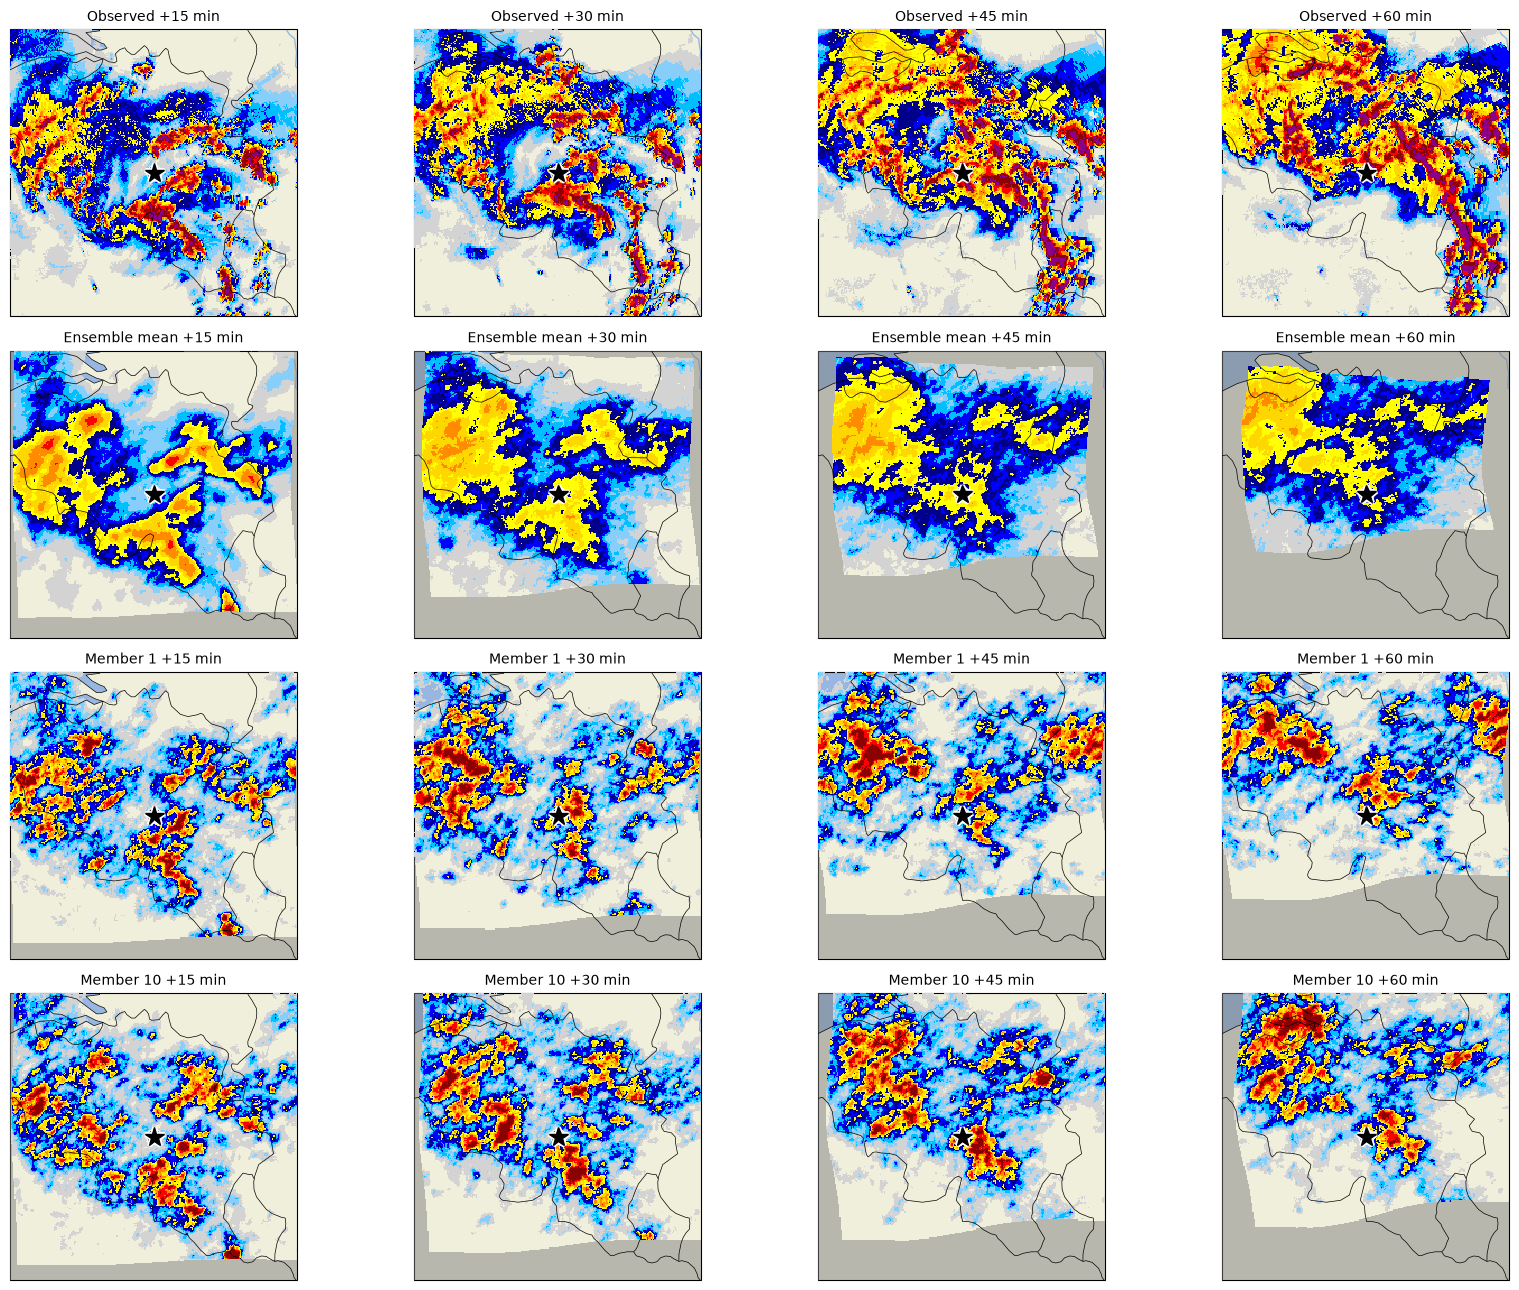

heaviest rain within 5 km at +25 min, when the observed peak occurred:
  observed         58.5 mm/h
  ensemble mean     6.4 mm/h
  wettest member   37.7 mm/h


In [26]:
ensemble_mean = nowcast_ens.mean(axis=0)

plt.figure(figsize=(17, 13))
rows = [(precip_obs, "Observed"), (ensemble_mean, "Ensemble mean"),
        (nowcast_ens[1], "Member 1"), (nowcast_ens[10], "Member 10")]
for r, (field, name) in enumerate(rows):
    for k, j in enumerate(range(2, 13, 3)):
        ax = site_map((4, 4, r * 4 + k + 1))
        plot_precip_field(field[j], geodata=metadata, ax=ax,
                          colorscale="STEPS-NL", colorbar=False)
        mark_site(ax, label=False)
        ax.set_title(f"{name} +{(j + 1) * 5} min", fontsize=10)
plt.tight_layout()
plt.show()

jpeak = int(truth_site.argmax())
print(f"heaviest rain within {NEIGHBOURHOOD_KM} km at +{(jpeak + 1) * 5} min, "
      f"when the observed peak occurred:")
print(f"  observed        {truth_site[jpeak]:5.1f} mm/h")
print(f"  ensemble mean   {site_max(ensemble_mean)[jpeak]:5.1f} mm/h")
print(f"  wettest member  {max(site_max(m)[jpeak] for m in nowcast_ens):5.1f} mm/h")

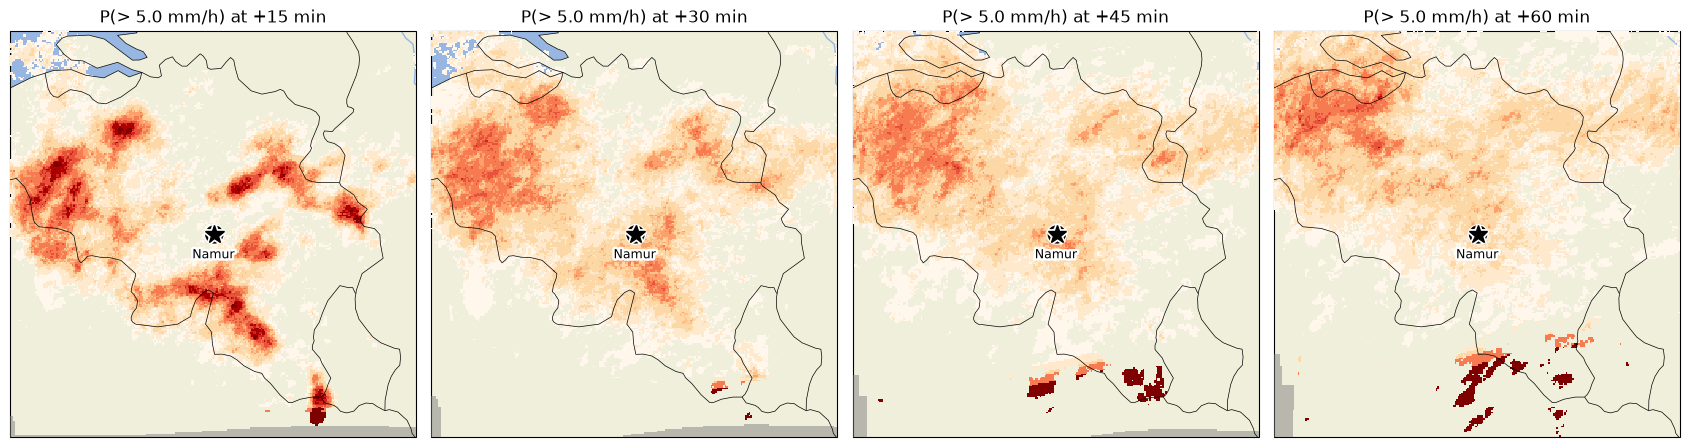

In [27]:
# The probability field: in how many members does each pixel exceed the threshold?
plt.figure(figsize=(17, 4.5))
for k, j in enumerate(range(2, 13, 3)):
    P = excprob(nowcast_ens[:, j], WARN_THR, ignore_nan=True)
    ax = site_map((1, 4, k + 1))
    plot_precip_field(P, geodata=metadata, ax=ax, ptype="prob", units="mm/h",
                      probthr=WARN_THR, colorbar=False)
    mark_site(ax)
    ax.set_title(f"P(> {WARN_THR} mm/h) at +{(j + 1) * 5} min")
plt.tight_layout()
plt.show()

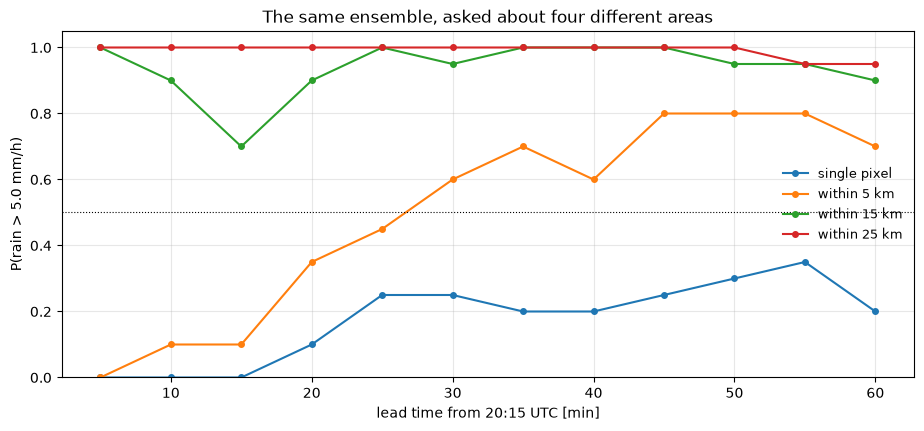

 lead     pixel      5 km     15 km     25 km |  observed
    5      0.00      0.00      1.00      1.00 |    1.1 mm/h
   10      0.00      0.10      0.90      1.00 |    1.7 mm/h
   15      0.00      0.10      0.70      1.00 |    1.7 mm/h
   20      0.10      0.35      0.90      1.00 |    1.7 mm/h
   25      0.25      0.45      1.00      1.00 |   58.5 mm/h
   30      0.25      0.60      0.95      1.00 |   49.7 mm/h
   35      0.20      0.70      1.00      1.00 |   37.8 mm/h
   40      0.20      0.60      1.00      1.00 |   46.1 mm/h
   45      0.25      0.80      1.00      1.00 |   48.5 mm/h
   50      0.30      0.80      0.95      1.00 |   58.1 mm/h
   55      0.35      0.80      0.95      0.95 |   58.3 mm/h
   60      0.20      0.70      0.90      0.95 |   13.5 mm/h


In [28]:
def neighbourhood_prob(ens, thr, radius_km):
    """P(rain exceeds thr anywhere within radius_km of the stage), per lead time.

    A member counts as an exceedance if ANY grid cell in the neighbourhood goes
    over the threshold - the same question the site series asks, put to each of
    the possible futures in turn.
    """
    m = disc(radius_km)
    return np.array([
        np.mean([ens[k, t][m].max() > thr for k in range(ens.shape[0])])
        for t in range(ens.shape[1])
    ])


probs = {r: neighbourhood_prob(nowcast_ens, WARN_THR, r) for r in RADII}

fig, ax = plt.subplots(figsize=(11, 4.5))
for r in RADII:
    ax.plot(lead, probs[r], "o-", ms=4,
            label="single pixel" if r == 0 else f"within {r} km")
ax.axhline(0.5, c="k", lw=0.8, ls=":")
ax.set_xlabel(f"lead time from {T0[-5:]} UTC [min]")
ax.set_ylabel(f"P(rain > {WARN_THR} mm/h)")
ax.set_ylim(0, 1.05)
ax.set_title("The same ensemble, asked about four different areas")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.3)
plt.show()

print(f"{'lead':>5} " + " ".join(f"{('pixel' if r == 0 else str(r) + ' km'):>9}" for r in RADII)
      + " |  observed")
for i, m in enumerate(lead):
    row = " ".join(f"{probs[r][i]:9.2f}" for r in RADII)
    print(f"{int(m):>5} {row} | {truth_site[i]:6.1f} mm/h")

In [29]:
# At what probability would you act? Below it you run the show, above it you clear
# the field. There is no neutral choice here: a missed evacuation and a needless one
# are both costly, and they are not costly in the same way.
P_DECISION = 0.5

p_site = neighbourhood_prob(nowcast_ens, WARN_THR, NEIGHBOURHOOD_KM)
crossed = np.argwhere(p_site >= P_DECISION)
observed_onset = first_exceedance(truth_site)
if len(crossed):
    lt = int(crossed[0, 0] + 1) * 5
    valid = str(times[T0_INDEX + int(crossed[0, 0]) + 1])[11:16]
    print(f"P first reaches {P_DECISION:.0%} at +{lt} min - a warning issued at "
          f"{T0[-5:]} UTC for {valid} UTC")
    if observed_onset is not None:
        print(f"the threshold was actually crossed at {label(observed_onset)}, so this "
              f"warning had {observed_onset - lt:+d} min of real lead time")
else:
    print(f"the ensemble never reaches {P_DECISION:.0%} within the hour - no warning")
print(f"maximum probability reached within {NEIGHBOURHOOD_KM} km: {p_site.max():.2f}")
print(f"maximum probability for the single pixel:      {probs[0].max():.2f}")

P first reaches 50% at +30 min - a warning issued at 20:15 UTC for 20:45 UTC
the threshold was actually crossed at +25 min, so this warning had -5 min of real lead time
maximum probability reached within 5 km: 0.80
maximum probability for the single pixel:      0.35


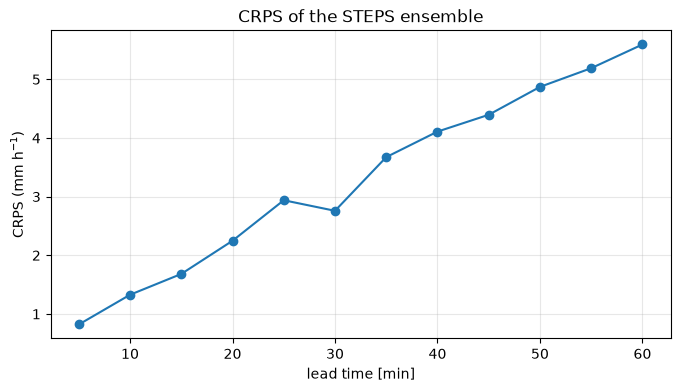

In [30]:
# Is the ensemble any good? CRPS first - the mean absolute error of an ensemble.
crps = [verification.probscores.CRPS(nowcast_ens[:, i], precip_obs[i])
        for i in range(N_LEADTIMES)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lead, crps, "o-")
ax.set_xlabel("lead time [min]")
ax.set_ylabel(r"CRPS (mm h$^{-1}$)")
ax.set_title("CRPS of the STEPS ensemble")
ax.grid(alpha=0.3)
plt.show()

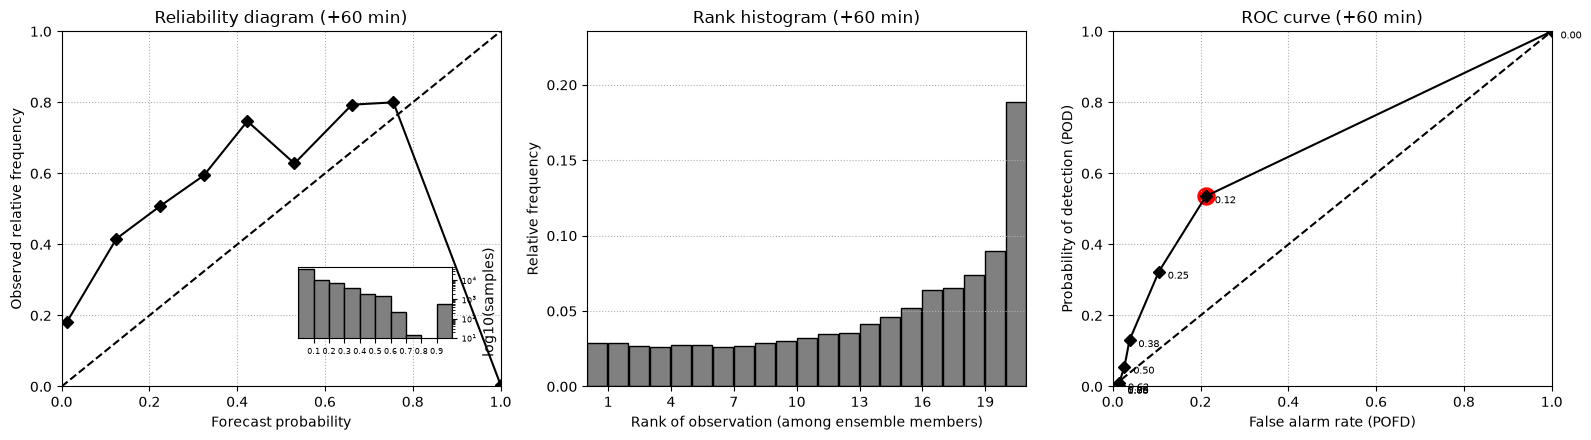

rank histogram counts: [ 784  780  717  704  734  736  704  723  776  813  865  935  952 1109
 1236 1398 1725 1762 1997 2428 5078]
the observation fell above every one of the 20 members in 19% of pixels
a reliable ensemble would put about 5% there


In [31]:
# Then the probability itself, at the last lead time.
probability_forecast = excprob(nowcast_ens[:, -1], WARN_THR, ignore_nan=True)
observed_last = precip_obs[-1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# each follows the same pysteps idiom: *_init, then *_accum, then plot_*
reldiag = verification.reldiag_init(WARN_THR)
verification.reldiag_accum(reldiag=reldiag, P_f=probability_forecast, X_o=observed_last)
verification.plot_reldiag(reldiag, axes[0])
axes[0].set_title(f"Reliability diagram (+{N_LEADTIMES * 5} min)")

rankhist = verification.rankhist_init(nowcast_ens.shape[0], WARN_THR)
verification.rankhist_accum(rankhist, nowcast_ens[:, -1], observed_last)
verification.plot_rankhist(rankhist, axes[1])
axes[1].set_title(f"Rank histogram (+{N_LEADTIMES * 5} min)")

roc = verification.ROC_curve_init(WARN_THR, n_prob_thrs=9)
verification.ROC_curve_accum(ROC=roc, P_f=probability_forecast, X_o=observed_last)
verification.plot_ROC(roc, axes[2], opt_prob_thr=True)
axes[2].set_title(f"ROC curve (+{N_LEADTIMES * 5} min)")

plt.tight_layout()
plt.show()

# The rank histogram as numbers, since the verdict has to cite it.
counts = rankhist["n"]
print(f"rank histogram counts: {counts.astype(int)}")
print(f"the observation fell above every one of the {nowcast_ens.shape[0]} members in "
      f"{counts[-1] / counts.sum():.0%} of pixels")
print(f"a reliable ensemble would put about {1 / (nowcast_ens.shape[0] + 1):.0%} there")

### 🔴 VERDICT 4: the probabilistic warning

This is the final verdict, and all three parts are required.

**(a)** State the probability that the threshold was exceeded at the site, at the lead time you
committed to in verdict three.

**(b)** State the lead time your warning would have had, using your `P_DECISION`. Say which
decision threshold you chose and why, remembering that clearing a festival field is not a
coat-and-umbrella decision. Then say what this same ensemble would have given you had you asked
about a single pixel instead.

**(c)** State how far that probability can be trusted. Cite your reliability diagram and your rank
histogram. Say explicitly whether the ensemble was underdispersed, meaning its members were too
similar to one another to cover what actually happened. If it was, restate (a) as a range, and say
in which direction the truth is likely to lie.

Then read your verdicts side by side. Where a verdict claims more confidence than your own
diagrams support, cross it out and rewrite it. That correction is the deliverable.

In [32]:
# (a) probability, (b) lead time and your decision threshold, (c) how far it can be trusted.
verdict_probabilistic = """
(a) At +30 min, the lead time I committed to in verdict three, the ensemble put the probability of
    exceeding 5 mm/h within 5 km of the stage at 0.60. It rose to 0.80 by +45 min.

(b) On a 50% rule the warning fires at +30 min, for rain that arrived at +25 min. The honest lead
    time is therefore around zero. The panel would have been telling the organiser to clear the
    field at roughly the moment the rain started. I would defend 0.5 for the decision to prepare,
    but not for the decision to stop the show. Clearing an open field is cheap set against not
    clearing it, and at 0.3 the ensemble fires at +20 min, genuinely ahead of the event.
    The comparison that matters most is with the single pixel. Asked about one 1 km cell, this
    same ensemble never exceeded 0.35 at any lead time. No threshold I could defend would ever
    have fired, and the panel would have concluded the storm was simply unforecastable. Asked
    about 5 km, it reaches 0.80. Nothing about the atmosphere changed between those two numbers.
    The area we chose to ask about was the difference between a useless product and an actionable
    warning, and that was our choice, not the weather's.

(c) Not far. The rank histogram is piled into its last bin. The observation fell above every one
    of the twenty members in far more of the domain than the 5% a reliable ensemble would put
    there. The ensemble is underdispersed and biased dry. That is the same failure the mean error
    showed in step 5, now visible as a property of the whole distribution rather than of one
    field. The reliability curve sits below the diagonal at the high-probability end, so where the
    ensemble was confident it was over-confident.
    Restating (a) as a range: the true probability of exceeding 5 mm/h within 5 km at +30 min was
    higher than 0.60. The error is one-directional, because an underdispersed, dry-biased ensemble
    understates this risk and cannot overstate it. If anything the panel should have acted sooner
    than its own numbers suggested.

    The correction. Verdict three claimed a 30-minute warning and said nothing about confidence.
    It was the most defensible statement available at the time, and it was still wrong in the
    direction that matters, under-forecasting the peak by half. Verdict four is better calibrated,
    but it came within one design decision of not being a warning at all. Against the 2 h 40 min
    ceiling from step 1, our methods delivered twenty to thirty minutes. Most of the available
    lead time was lost not to the atmosphere but to choices we made about how to ask the question.
"""

---
## The panel's report: the verdicts side by side

No answer key judges these. What teaches you is the gap between what you claimed at step 1, at
step 5 and at step 6, together with the verification numbers you computed yourself.

In [33]:
for title, text in [
    ("VERDICT 1  - the ceiling, no method used", verdict_1),
    ("COMMITMENT A - what step 2 rested on", commitment_a),
    ("VERDICT 2  - the motion field, committed before verification", verdict_2_motion),
    ("COMMITMENT B - uncertainty from the method", commitment_b),
    ("VERDICT 3  - the deterministic warning", verdict_deterministic),
    ("VERDICT 4  - the probabilistic warning", verdict_probabilistic),
]:
    print("=" * 78)
    print(title)
    print("=" * 78)
    print(text.strip() or "   [ not answered ]")
    print()

VERDICT 1  - the ceiling, no method used
(a) Taking the site as the heaviest rain within 5 km of the stage, the threshold was first
    exceeded at 20:40 UTC. On the single pixel it was 20:45. On a 15 km circle it had already been
    exceeded before the evening started, which is the first sign that the radius is doing real
    work.

(b) On the 18:00 frame there is already a coherent, growing mass of echo about 70 km south of
    Namur. By 18:30 it is unmistakable, roughly 90 km south and expanding fast. It is moving
    north-northeast at the speed the loop shows, so it is pointed at the site. I would defend
    18:00 as the first frame on which a duty forecaster should have flagged it for a site at
    Namur.

(c) The ceiling is 20:40 minus 18:00, which is 2 h 40 min.
    What limits it is not the nowcasting method. It is when the storm first existed on the radar
    at all. No radar-based warning for this site could have had more than about two and a half
    hours of lead time, wh

### What the panel actually learned

The ceiling was never the method's to give. Step 1 fixed roughly two hours and forty minutes of
possible lead time, set by when the storm first appeared on radar at all. Both nowcasts delivered
a fraction of that. The difference is not a failure of pysteps. It is what happens when a method
that carries patterns forward meets a storm that is still growing. Extrapolation has no mechanism
for intensification, and this storm was intensifying.

How you ask the question decides whether you get an answer at all. The same ensemble, on the same
evening, said 0.35 about a pixel and 0.80 about a five-kilometre circle. Precipitation is not a
point quantity, and a forecast asked for a point answer will fail whatever method produced it.
Widen the neighbourhood too far, though, and the answer becomes yes for ever and means nothing.
That choice belongs to the forecaster. It should be argued for in the open rather than defaulted
into.

A confident number is not a trustworthy one. Verdict three stated a single warning time and could
not qualify it, while its false alarm ratio approached one in two.

The ensemble mean is the wrong field to hand a decision maker. The members held the intense cells.
The mean averaged them away, which is exactly the property the course attributes to the
error-minimising methods.

The probability needed checking too. The rank histogram is the last word here. An underdispersed
ensemble that is also biased dry produces probabilities that look precise and understate the risk.
A panel that quoted verdict four's number without reading its own rank histogram would have been
confidently wrong in the same direction as everyone before it.

If your verdicts claimed more than your own diagrams support, say so in the report. That
correction is the point of the exercise.

## References

**Literature**

1. Bouguet, J.-Y. (2001). *Pyramidal implementation of the affine Lucas Kanade feature tracker:
   description of the algorithm.* Intel Corporation.
2. Bowler, N. E., Pierce, C. E. and Seed, A. W. (2006). STEPS: a probabilistic precipitation
   forecasting scheme which merges an extrapolation nowcast with downscaled NWP. *Quarterly
   Journal of the Royal Meteorological Society*, 132(620), 2127 to 2155. doi:10.1256/qj.04.100
3. Ebert, E., Wilson, L., Weigel, A., Mittermaier, M., Nurmi, P., Gill, P., Göber, M., Joslyn, S.,
   Brown, B., Fowler, T. and Watkins, A. (2013). Progress and challenges in forecast verification.
   *Meteorological Applications*, 20(2), 130 to 139. doi:10.1002/met.1392
4. Germann, U. and Zawadzki, I. (2002). Scale-dependence of the predictability of precipitation
   from continental radar images. Part I: description of the methodology. *Monthly Weather
   Review*, 130(12), 2859 to 2873. doi:10.1175/1520-0493(2002)130<2859:SDOTPO>2.0.CO;2
5. Germann, U. and Zawadzki, I. (2004). Scale-dependence of the predictability of precipitation
   from continental radar images. Part II: probability forecasts. *Journal of Applied
   Meteorology*, 43(1), 74 to 89. doi:10.1175/1520-0450(2004)043<0074:SDOTPO>2.0.CO;2
6. Hersbach, H. (2000). Decomposition of the continuous ranked probability score for ensemble
   prediction systems. *Weather and Forecasting*, 15(5), 559 to 570.
   doi:10.1175/1520-0434(2000)015<0559:DOTCRP>2.0.CO;2
7. Imhoff, R. O., Brauer, C. C., Overeem, A., Weerts, A. H. and Uijlenhoet, R. (2020). Spatial and
   temporal evaluation of radar rainfall nowcasting techniques on 1,533 events. *Water Resources
   Research*, 56(8), e2019WR026723. doi:10.1029/2019WR026723
8. Laroche, S. and Zawadzki, I. (1995). Retrievals of horizontal winds from single-Doppler
   clear-air data by methods of cross correlation and variational analysis. *Journal of
   Atmospheric and Oceanic Technology*, 12(4), 721 to 738.
   doi:10.1175/1520-0426(1995)012<0721:ROHWFS>2.0.CO;2
9. Pulkkinen, S., Nerini, D., Pérez Hortal, A. A., Velasco-Forero, C., Seed, A., Germann, U. and
   Foresti, L. (2019). Pysteps: an open-source Python library for probabilistic precipitation
   nowcasting (v1.0). *Geoscientific Model Development*, 12, 4185 to 4219.
   doi:10.5194/gmd-12-4185-2019
10. Roberts, N. M. and Lean, H. W. (2008). Scale-selective verification of rainfall accumulations
    from high-resolution forecasts of convective events. *Monthly Weather Review*, 136(1), 78 to
    97. doi:10.1175/2007MWR2123.1
11. Ruzanski, E., Chandrasekar, V. and Wang, Y. (2011). The CASA nowcasting system. *Journal of
    Atmospheric and Oceanic Technology*, 28(5), 640 to 655. doi:10.1175/2011JTECHA1496.1
12. Seed, A. W. (2003). A dynamic and spatial scaling approach to advection forecasting. *Journal
    of Applied Meteorology*, 42(3), 381 to 388. doi:10.1175/1520-0450(2003)042<0381:ADASSA>2.0.CO;2

**Software documentation.** Everything this notebook calls is documented at
<https://pysteps.readthedocs.io>. The pages used above are `pysteps.utils.conversion` for the Z-R
relation and the dBR transform, `pysteps.motion` for the three optical flow methods,
`pysteps.extrapolation.semilagrangian` for the advection scheme, `pysteps.nowcasts` for
extrapolation and STEPS, `pysteps.postprocessing.ensemblestats` for exceedance probabilities, and
`pysteps.verification` for every score. The bibliography that pysteps itself keeps, at
<https://pysteps.readthedocs.io/en/stable/zz_bibliography.html>, maps each function to the paper
behind it.

**Data.** RADCLIM, Royal Meteorological Institute of Belgium, released under CC-BY-4.0 and served
through the MLCast community catalog on ECMWF object storage.

<details>
<summary><b>Instructor notes</b>, on the design behind the six steps (click to expand)</summary>

**Version A: the incident review.** The learner joins a review panel convened after the event. The
panel's deliverable is a written verdict stating whether a warning was possible and from what
time. The six steps supply the evidence, one piece each, and the learner commits to a verdict
three separate times as that evidence accumulates.

**Step 1, obtain the radar data and select the frames.** This settles the ceiling on the answer
before any nowcast exists. A learner who runs the methods first will blame the short lead time on
a weakness in the method, when the real constraint is the arrival time of the first echo. The step
also carries the point-against-area decision. The pixel series swings by more than 10 mm/h between
consecutive frames. A 15 km circle already contains 44 mm/h at the first lead time. The mean over
a circle dilutes the peak the panel cares about. The learner has to land on the maximum over a
moderate neighbourhood, and `NEIGHBOURHOOD_KM` is the most consequential blank in the notebook.

**Step 2, motion by eye.** This is deliberately not a black box handed over by an unnamed desk.
The learner reads speed and bearing off the loop themselves, so the debt named in Commitment A is
their own. A due-north estimate at 50 km/h puts the threshold at the site later than Lucas-Kanade
does, but with a higher peak, so it is not obviously worse. That is the point. There are two
answers and no evidence yet with which to choose between them.

**Step 3, compute the optical flow three ways.** Requiring the written justification before
feedback is what separates a reasoned choice from a lucky one. On this case DARTS is decisively
wrong, at under half the true speed, and it produces no warning at all. That gives the step real
teeth.

**Step 4, two frames against three.** A note for the instructor. On this case Lucas-Kanade is
remarkably stable, and the two estimates agree to within one output step. The step as originally
briefed expected the learner to watch temporal smoothing stabilise a noisy estimate, and here
there is nothing to see. The honest reading is the better lesson, and the notebook leads there.
Frame count moved the answer by less than 5 minutes, while the method choice was the difference
between a warning and none. For a visibly unstable pair, try the frames during the 19:45 to 20:10
shower.

**Step 5, the deterministic nowcast and verdict two.** The panel gets something defensible and
immediately meets its limit. ETS has been removed. POD, FAR and ME remain, and FSS across
neighbourhood scales carries the scale lesson from the verification side.

**Step 6, the probabilistic nowcast and the final verdict.** This is the only step that answers
the organiser's real question. The members preserve the intense cells that the mean smooths away.
The reliability diagram and the rank histogram then test the probability itself. This ensemble is
underdispersed on this case. The rank histogram's last bin holds about 19% of pixels against the
5% a reliable 20-member ensemble would put there. The panel's confident-looking number was
therefore overconfident, and the verdict has to say so.

**Feedback design.** The verdicts sit side by side at the end, and no answer key judges them. What
teaches is the gap between step 1, step 5 and step 6, together with the numbers the learner
computed. Where a verdict claims more than the reliability diagram supports, the notebook says so
plainly rather than encouragingly.

**Case facts, for marking.** Observed within 5 km of the stage: threshold first exceeded 20:40,
peak 58 mm/h. Single pixel: 20:45, peak 41, mean frame-to-frame change 13 mm/h. Ceiling from
step 1: about 2 h 40 min. LK and VET about 4.9 px per 5 min, or 16 m/s. DARTS 1.8 px, or 6 m/s. By
eye 4.2 px. Runtimes on the 256 km box: LK 0.6 s, DARTS 4 s, VET 34 s, STEPS with 20 members 13 s.
Deterministic, using the 5 km maximum: threshold at +30 min against +25 observed, peak 29 against
58, POD 0.29 and FAR 0.47 at +30 min. FSS stays at or above 0.5 out to +20 min at 1 km, +30 at
5 km, +35 at 15 km, and beyond +60 at 40 km. Ensemble P(> 5 mm/h): 0.35 maximum at the pixel,
**0.80** at 5 km crossing 0.5 at +30 min, saturated at 1.00 by 25 km.

</details>